# 16_3 · G/F con crecimiento por azúcar disponible e identificabilidad

Ambas simulaciones usan los parámetros químicos guardados del 16_2, sus pulsos, sus entradas de temperatura, sus condiciones iniciales y su capa de CO₂. La variante del EKF 16 permite que el crecimiento y la captación de YAN continúen mientras quede glucosa o fructosa. Cada azúcar agotado deja de aportar al crecimiento. Se compara una sola modificación de la dinámica en LAB004–009 y LAB016–024.

In [1]:
from pathlib import Path
from types import FunctionType
import json

import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/wine_fermentation").is_dir())
source, = (ROOT / "notebooks").glob("16_2_*.source.ipynb")
calibration = nbformat.read(source, 4)
saved = nbformat.read(source.with_name(source.name.replace(".source.", ".executed.")), 4)
assert [cell.source for cell in calibration.cells] == [cell.source for cell in saved.cells]
[output] = [o.text.split("PARÁMETROS QUÍMICOS COMPLETOS", 1)[1].lstrip()
            for o in saved.cells[5].outputs
            if o.output_type == "stream" and "PARÁMETROS QUÍMICOS COMPLETOS" in o.text]
theta, _ = json.JSONDecoder().raw_decode(output)

def reference(index, start=None, stop=None):
    code = calibration.cells[index].source
    if start is not None:
        assert code.count(start) == 1
        code = code[code.index(start):]
    if stop is not None:
        assert code.count(stop) == 1
        code = code[:code.index(stop)]
    return code

setup = {"__name__": "__main__", "display": lambda *_: None}
for code in (reference(1, stop="start=kin.normalize_parameters"),
             reference(3),
             reference(12, stop="cores,caches,activation=build_curves(theta)"),
             reference(12, start="KLA, GAIN =", stop="curves={lab:gas(lab,KLA,GAIN)"),
             reference(13)):
    exec(compile(code, source.name, "exec"), setup)
kin = setup["kin"]
assert set(theta) == set(kin.PARAMETERS)
display(pd.Series(theta, name="Parámetros guardados del 16_2"))
print("Capa de CO₂ del 16_2", setup["HOLDOUT_GAS_PARAMS"])

,LAB,original_g_L,viables_millones_mL,corregido_g_L
0,LAB004,0.3939,10.75,0.3225
1,LAB005,0.4932,11.25,0.3375


Pares de réplicas: 23 sigma réplica: 0.1189341469231937 sigmaX de referencia del 16: 0.5


,LAB,agotamiento_h,corte_YAN_h,N0_mg,pulsos,X,N,G,F,E
0,LAB004,91.0,103.0,230.76,"((68.5, 0.08),)",10,8,12,12,4
1,LAB005,91.0,103.0,227.30,"((68.5, 0.08),)",10,8,12,12,4
2,LAB006,122.0,134.0,229.12,"((100.0, 0.08),)",12,9,14,14,4
3,LAB007,88.0,100.0,239.04,"((65.5, 0.08),)",11,8,12,12,5
4,LAB008,88.0,100.0,239.22,"((65.5, 0.08),)",11,8,12,12,5
5,LAB009,64.0,76.0,237.40,"((41.84615384615385, 0.08),)",10,6,11,11,4


,LAB,t_h,original_mg,usado_mg,estado
0,LAB004,0.0,230.76,230.76,Inicial
1,LAB004,19.0,182.72,182.72,Usado
2,LAB004,26.0,157.42,157.42,Usado
3,LAB004,43.0,60.16,60.16,Usado
4,LAB004,50.0,19.00,0.00,Transformado
...,...,...,...,...,...
74,LAB009,88.0,17.00,NaN,Excluido
75,LAB009,96.0,19.00,NaN,Excluido
76,LAB009,120.0,5.00,NaN,Excluido
77,LAB009,144.0,25.00,NaN,Excluido


Observaciones en el objetivo {'X': 64, 'N': 47, 'G': 73, 'F': 73, 'E': 26}


,LAB,X,N,G,F,E,pulsos,corte_h
0,LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08648648648648648),)",166.000000
1,LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08888888888888889),)",172.333333
2,LAB021,0.270000,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08648648648648648),)",166.000000
3,LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)",151.100000
4,LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.28),)",141.000000
5,LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)",141.000000


,Pulso [h],Volumen [L],Aporte [mg N/L]
LAB,,,
LAB022,113.633,1.85,99.906
LAB023,113.783,1.85,99.906
LAB024,113.883,1.85,99.906


mu0         0.086722
betaG0      0.428291
betaF0      0.593521
Kn0         0.008258
Kg0         4.400775
Kf0        19.296084
Kig0       80.490799
Kie0      168.120412
Kd0         0.000440
Yxn         5.272368
Yxg         0.966094
Yxf         1.109896
Yeg         0.459547
Yef         0.510598
m0          0.018339
Name: Parámetros guardados del 16_2, dtype: float64

Capa de CO₂ del 16_2 (0.15007991020720535, 0.6460643588058115)


## Integración y regla de crecimiento

Se localiza cuándo cada azúcar llega a cero y se integra de nuevo desde ese punto. El mismo manejo de eventos se usa en ambas simulaciones. En la producción de CO₂, el aporte de crecimiento sigue la misma regla que los balances químicos.

In [2]:
BASE = "Regla del 16_2"
AVAILABLE = "Regla del EKF 16"
LABELS = (BASE, AVAILABLE)
SUGARS = np.array([2, 3])
solve_ivp = setup["solve_ivp"]

def integrate_sugar_events(rhs, interval, initial, *, t_eval, **options):
    start, end = interval
    state = np.array(initial, copy=True)
    active = list(SUGARS[state[SUGARS] > 0.])
    pieces_t, pieces_y = [], []
    remaining = np.asarray(t_eval)
    while start < end:
        frozen = list(set(SUGARS) - set(active))

        def stage_rhs(t, y):
            physical = y.copy()
            physical[active] = np.maximum(physical[active], np.finfo(float).tiny)
            physical[frozen] = 0.
            derivative = rhs(t, physical)
            derivative[frozen] = 0.
            return derivative

        events = []
        for index in active:
            def depleted(t, y, index=index):
                return y[index]
            depleted.terminal = True
            depleted.direction = -1
            events.append(depleted)

        result = solve_ivp(stage_rhs, (start, end), state, t_eval=remaining,
                           events=events or None, **options)
        if not result.success:
            return result
        pieces_t.append(np.asarray(result.t))
        pieces_y.append(np.asarray(result.y).reshape(len(initial), -1))
        if result.status != 1:
            break
        [hit] = [i for i, times in enumerate(result.t_events) if len(times)]
        start = result.t_events[hit][0]
        state = result.y_events[hit][0].copy()
        state[active.pop(hit)] = 0.
        remaining = remaining[remaining > start]

    result.t = np.concatenate(pieces_t)
    result.y = np.concatenate(pieces_y, axis=1)
    np.testing.assert_array_equal(result.t, t_eval)
    return result

# Mantener el integrador, los pulsos y los tiempos de evaluación del 16_2.
simulate_source = reference(3, start="def simulate(b,p):", stop="def with_jumps")
old_guard = simulate_source[simulate_source.index("  if y[2]<=0 or y[3]<=0:"):
                            simulate_source.index("  return out")]
new_guard = '''  if y[2]<=0 or y[3]<=0:
   q=kin.kinetic_terms(p,kin.temperature_at(b,t),*y);growth=q['mu']*max(float(y[0]),0)
   if y[2]<=0 and y[3]<=0:
    out[0]-=growth;out[1]+=growth/p['Yxn']
   if y[2]<=0:
    out[2]+=growth/p['Yxg']
   if y[3]<=0:
    out[3]+=growth/p['Yxf']
'''
holdout_source = reference(14, start="def run_holdout(theta):",
                           stop="holdout_kinetic, holdout_plot, holdout_gas, holdout_mean_gas = run_holdout(theta)")
historical_source = reference(12, start="def build_curves(parameters):", stop="PCO2_BAR=1.0")

training = {batch.batch: batch for batch in setup["treated"]}
historical = setup["batches"]
recent = setup["holdout_batches"]
batches = {**training, **historical, **recent}
assert set(batches) == {f"LAB{n:03}" for n in (*range(4, 10), *range(16, 25))}
trajectories, gas_curves, recent_gas, training_raw = {}, {}, {}, {}

for label in LABELS:
    context = {**setup, "solve_ivp": integrate_sugar_events}
    for name in ("configure_gas", "gas"):
        function = setup[name]
        context[name] = FunctionType(function.__code__, context, argdefs=function.__defaults__)
    chemistry, history, holdout = simulate_source, historical_source, holdout_source
    if label == AVAILABLE:
        assert chemistry.count(old_guard) == 1
        chemistry = chemistry.replace(old_guard, new_guard)
        history = history.replace("y[2]<=0 or y[3]<=0", "y[2]<=0 and y[3]<=0")
        holdout = holdout.replace("y[2] > 0 and y[3] > 0", "y[2] > 0 or y[3] > 0")

    exec(compile(chemistry + history + holdout, source.name, "exec"), context)
    context["simulate_holdout"] = context["simulate"]
    training_raw[label] = {lab: context["simulate"](batch, theta) for lab, batch in training.items()}
    cores, caches, activation = context["build_curves"](theta)
    context.update(caches=caches, activation=activation)
    context["configure_gas"](cores)
    gas_curves[label] = {lab: context["gas"](lab, *setup["HOLDOUT_GAS_PARAMS"]) for lab in historical}
    holdout_cores, _, holdout_gas, recent_gas[label] = context["run_holdout"](theta)
    gas_curves[label].update(holdout_gas)
    trajectories[label] = {**training_raw[label], **cores, **holdout_cores}

# Verificar condiciones iniciales, pulsos y mallas comunes.
for lab, batch in batches.items():
    a, b = (trajectories[label][lab] for label in LABELS)
    np.testing.assert_array_equal(a.index, b.index)
    np.testing.assert_array_equal(a.iloc[0], b.iloc[0])
    for frame in (a, b):
        assert (frame.to_numpy() >= 0.).all()
        received = [(j["t"], j["after"][1] - j["before"][1]) for j in frame.attrs["pulse_jumps"]]
        np.testing.assert_allclose(received, batch.pulses["N"], atol=1e-12, rtol=0.)
    # Las curvas deben coincidir antes de que se agote el primer azúcar.
    both = (a.G > 0.) & (a.F > 0.)
    stops = np.flatnonzero(~both.to_numpy())
    last = stops[0] if len(stops) else len(a)
    np.testing.assert_allclose(a.iloc[:last], b.iloc[:last], atol=2e-7, rtol=2e-6)

print(f"{len(batches)} lotes y {len(batches) * len(LABELS)} simulaciones químicas verificadas.")

15 lotes y 30 simulaciones químicas verificadas.


## Residuos y agotamiento de azúcar

En LAB004–009 se usa el soporte y la ponderación del objetivo histórico. Los RMSE químicos excluyen la condición inicial. Para LAB016–018, la referencia de G+F procede de densidad. En LAB022–024, el flujo de CO₂ se compara en medias de 30 minutos y conserva los huecos de la medición.

In [3]:
VARS = {
    "X": ("Biomasa viable", "g/L", 1.), "N": ("YAN", "mg N/L", 1000.),
    "G": ("Glucosa", "g/L", 1.), "F": ("Fructosa", "g/L", 1.),
    "GF": ("G+F", "g/L", 1.), "E": ("Etanol", "g/L", 1.),
    "CO2": ("Flujo de CO₂", "g/(L·h)", 1.),
}
recent_columns = {"X": ("holdout_biomass", "X_g_L"), "N": ("holdout_chemistry", "YAN for plot"),
                  "G": ("holdout_chemistry", "GLUCOSE-320"), "F": ("holdout_chemistry", "Fructose (derived)"),
                  "GF": ("holdout_chemistry", "GLU-FRU-320")}
v = setup["v"]

def observed(lab, state):
    batch = batches[lab]
    factor = VARS[state][2]
    horizon = v.horizons[lab] if lab in historical else batch.time[-1]
    if lab in training:
        if state == "CO2":
            return pd.Series(dtype=float)
        values = batch.observations["G"] + batch.observations["F"] if state == "GF" else batch.observations[state]
        times = batch.time
        values = factor * values
    elif state == "CO2":
        if lab in recent:
            common_windows = recent_gas[BASE][lab].index
            return setup["holdout_flow"][lab].reindex(common_windows).dropna()
        frame = setup["obs"][lab]
        times, values = frame.time_h.to_numpy(), frame.co2_raw_g_l_h.to_numpy()
    elif lab in recent:
        if state not in recent_columns:
            return pd.Series(dtype=float)
        table, column = recent_columns[state]
        frame = setup[table]
        samples = frame.loc[frame.lab.eq(lab) & frame["sample"].ne("01")]
        times, values = samples.hours.to_numpy(), samples[column].to_numpy()
    elif lab in setup["TRAIN"]:
        frame = setup["chemical_observations"](v.chem, lab, state)
        times, values = frame.t_h.to_numpy(), factor * frame[setup["CHEMICAL_COLUMNS"][state]].to_numpy()
    elif state == "X":
        frame = v.biomass.loc[v.biomass.lab.eq(lab)]
        times, values = frame.t_h.to_numpy(), frame.X_viable_g_l.to_numpy()
    elif state == "GF":
        frame = v.density.loc[v.density.lab.eq(lab)]
        times, values = frame.t_h.to_numpy(), 2.5 * (frame.density_g_l.to_numpy() - 1000.)
    else:
        return pd.Series(dtype=float)
    mask = np.isfinite(values) & (times > batch.time[0]) & (times <= horizon)
    return pd.Series(values[mask], index=times[mask]).sort_index()

def predicted(label, lab, state, *, plot=False):
    if state == "CO2":
        return recent_gas[label][lab] if lab in recent else gas_curves[label][lab]["qpred"]
    frame = trajectories[label][lab]
    if plot:
        frame = setup["with_jumps"](frame)
    return VARS[state][2] * frame[state]

samples = {(lab, state): observed(lab, state) for lab in batches for state in VARS}
rows = []
for (lab, state), obs in samples.items():
    if obs.empty:
        continue
    row = {"LAB": lab, "Variable": state, "n": len(obs)}
    for label in LABELS:
        pred = predicted(label, lab, state)
        errors = np.interp(obs.index, pred.index, pred.values) - obs.values
        row[label] = np.sqrt(np.mean(errors**2))
    row["Δ RMSE"] = row[AVAILABLE] - row[BASE]
    rows.append(row)
rmse = pd.DataFrame(rows).set_index(["LAB", "Variable"])
display(rmse.round(4))

weighted = {}
for label in LABELS:
    residuals = [(trajectories[label][b.batch][state].to_numpy()[mask] - b.observations[state][mask])
                 / setup["sigma"](state, b.observations[state][mask])
                 for b, state, mask in setup["support"]]
    weighted[label] = np.mean(np.concatenate(residuals)**2)
print("MSE ponderado LAB004–009:", weighted)
np.testing.assert_allclose(weighted[BASE], 4.715502281177189, rtol=2e-5)

summary = []
for lab, batch in batches.items():
    a, b = (trajectories[label][lab] for label in LABELS)
    delta = (a - b).abs().max()
    row = {"LAB": lab, "Δ máximo X [g/L]": delta.X, "Δ máximo N [mg N/L]": 1000 * delta.N}
    for label, frame in zip(LABELS, (a, b)):
        first = frame.index[(frame.G <= 1e-8) | (frame.F <= 1e-8)]
        row[f"Primer azúcar agotado [h] · {label}"] = first[0] if len(first) else np.nan
        row[f"YAN final [mg N/L] · {label}"] = 1000 * frame.N.iloc[-1]
    summary.append(row)
summary = pd.DataFrame(summary).set_index("LAB")
display(summary.round(4))
print(summary.round(4).to_string())
print(rmse.loc[["LAB022", "LAB023", "LAB024"]].round(4).to_string())

n  Regla del 16_2  Regla del EKF 16  Δ RMSE
LAB    Variable                                               
LAB004 X          10          0.2316            0.2316  0.0000
       N           8         28.2940           28.2940  0.0000
       G          12          3.5450            3.5450  0.0000
       F          12          7.0687            7.0687  0.0000
       GF         12         10.5070           10.5070  0.0000
...              ...             ...               ...     ...
LAB024 N           6         77.4098           80.3601  2.9502
       G           5          8.6883            8.6883  0.0000
       F           5         11.9049           12.0053  0.1004
       GF          5         18.8707           18.9449  0.0742
       CO2       378          0.1765            0.1765  0.0001

[84 rows x 4 columns]

MSE ponderado LAB004–009: {'Regla del 16_2': 4.715502281177189, 'Regla del EKF 16': 4.715502281177189}


,Δ máximo X [g/L],Δ máximo N [mg N/L],Primer azúcar agotado [h] · Regla del 16_2,YAN final [mg N/L] · Regla del 16_2,Primer azúcar agotado [h] · Regla del EKF 16,YAN final [mg N/L] · Regla del EKF 16
LAB,,,,,,
LAB004,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB005,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB006,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB007,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB008,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB009,0.0000,0.0000,146.0000,0.0000,146.0000,0.0
LAB019,0.0000,0.0000,178.0833,0.0000,178.0833,0.0
LAB020,0.0000,0.0000,NaN,0.0000,NaN,0.0
LAB021,0.0000,0.0000,163.0833,0.0000,163.0833,0.0


        Δ máximo X [g/L]  Δ máximo N [mg N/L]  Primer azúcar agotado [h] · Regla del 16_2  YAN final [mg N/L] · Regla del 16_2  Primer azúcar agotado [h] · Regla del EKF 16  YAN final [mg N/L] · Regla del EKF 16
LAB                                                                                                                                                                                                                
LAB004            0.0000               0.0000                                         NaN                               0.0000                                           NaN                                    0.0
LAB005            0.0000               0.0000                                         NaN                               0.0000                                           NaN                                    0.0
LAB006            0.0000               0.0000                                         NaN                               0.0000                          

## Trayectorias de los dos modelos

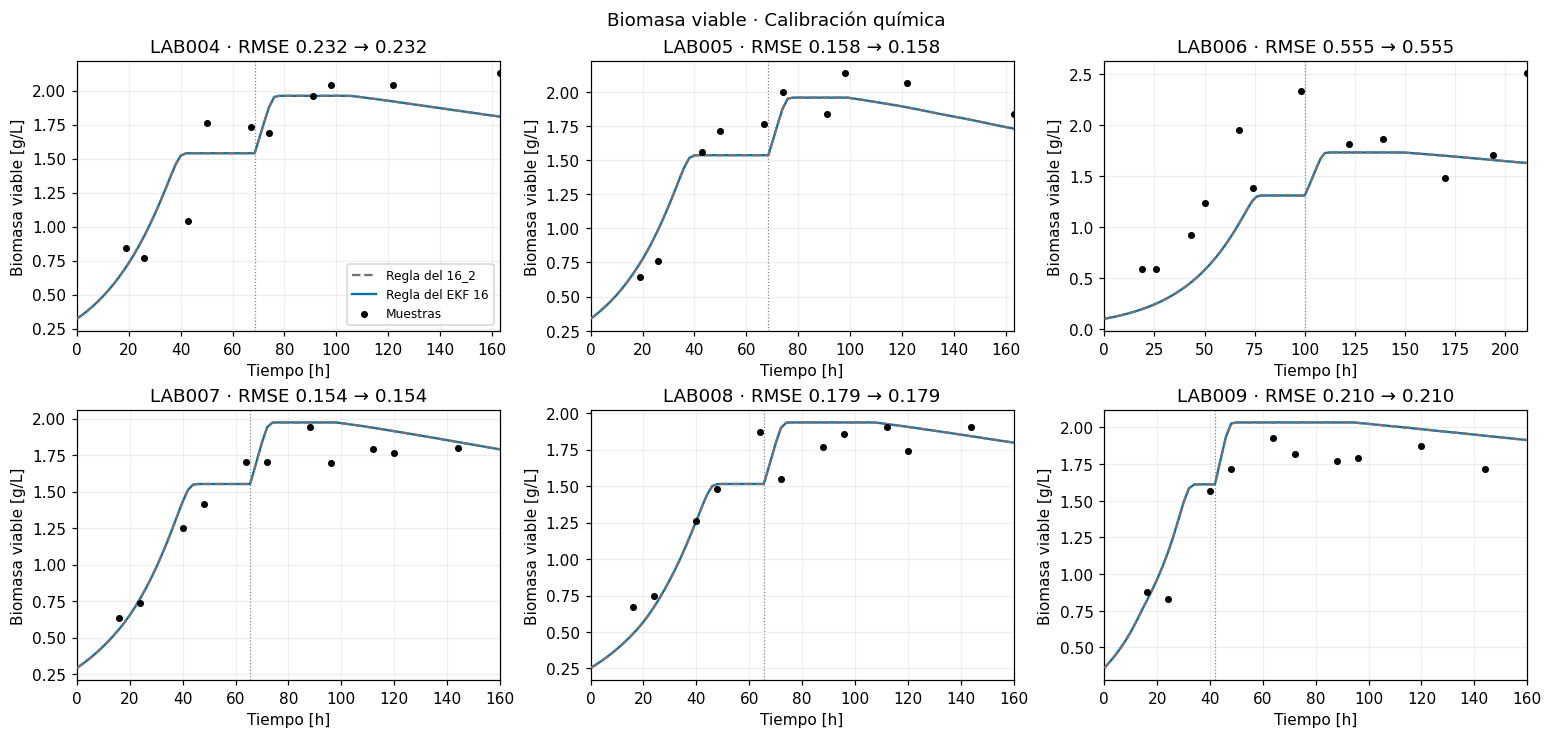

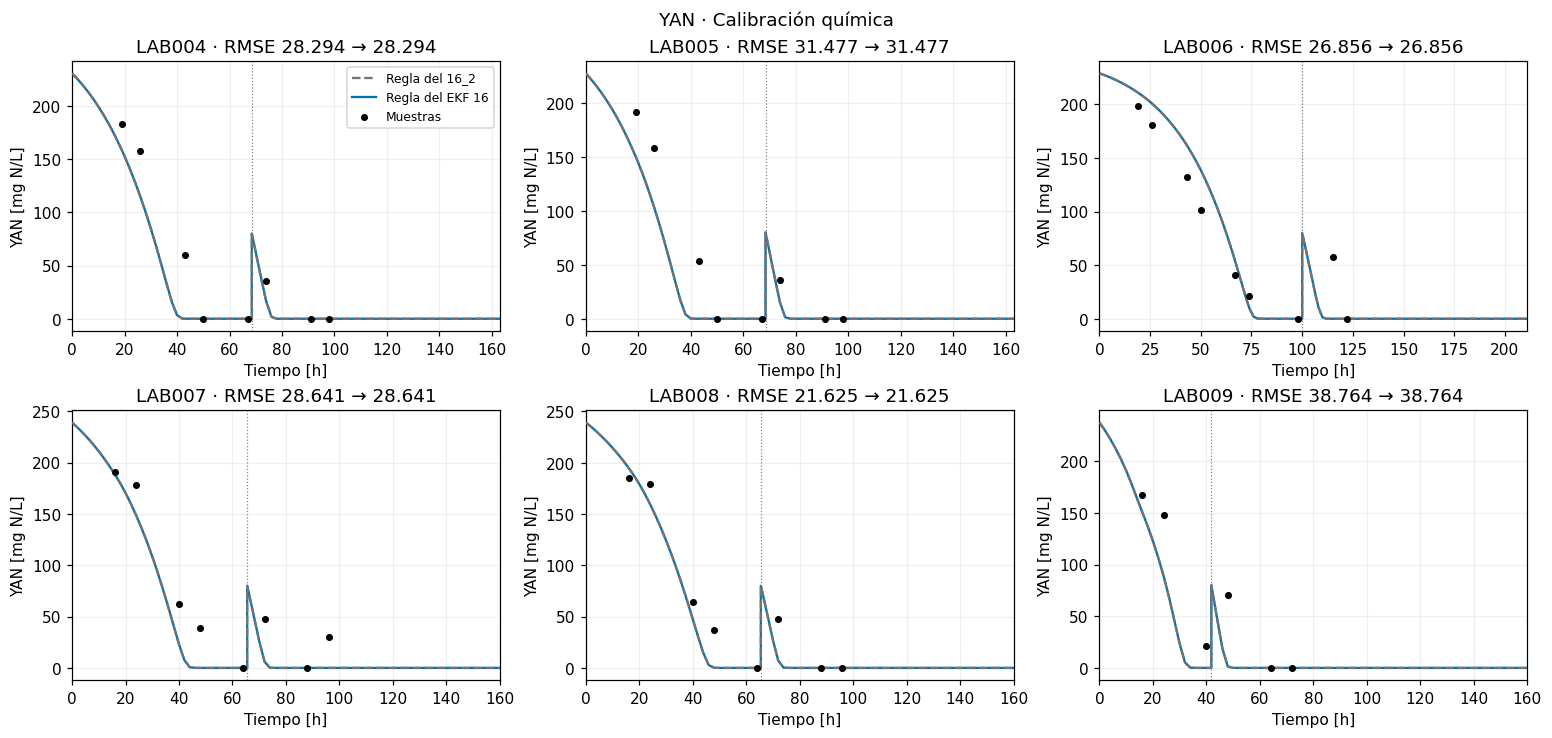

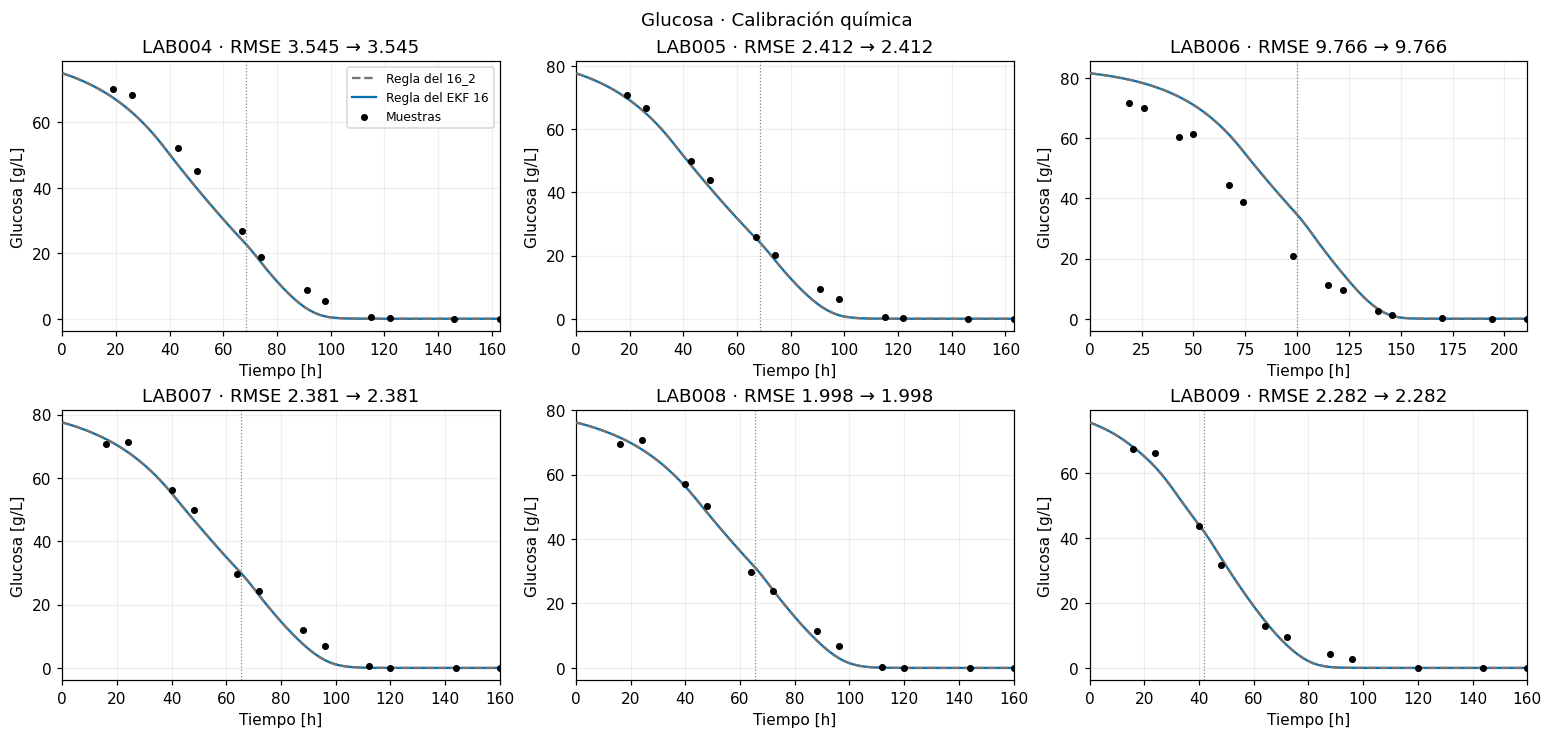

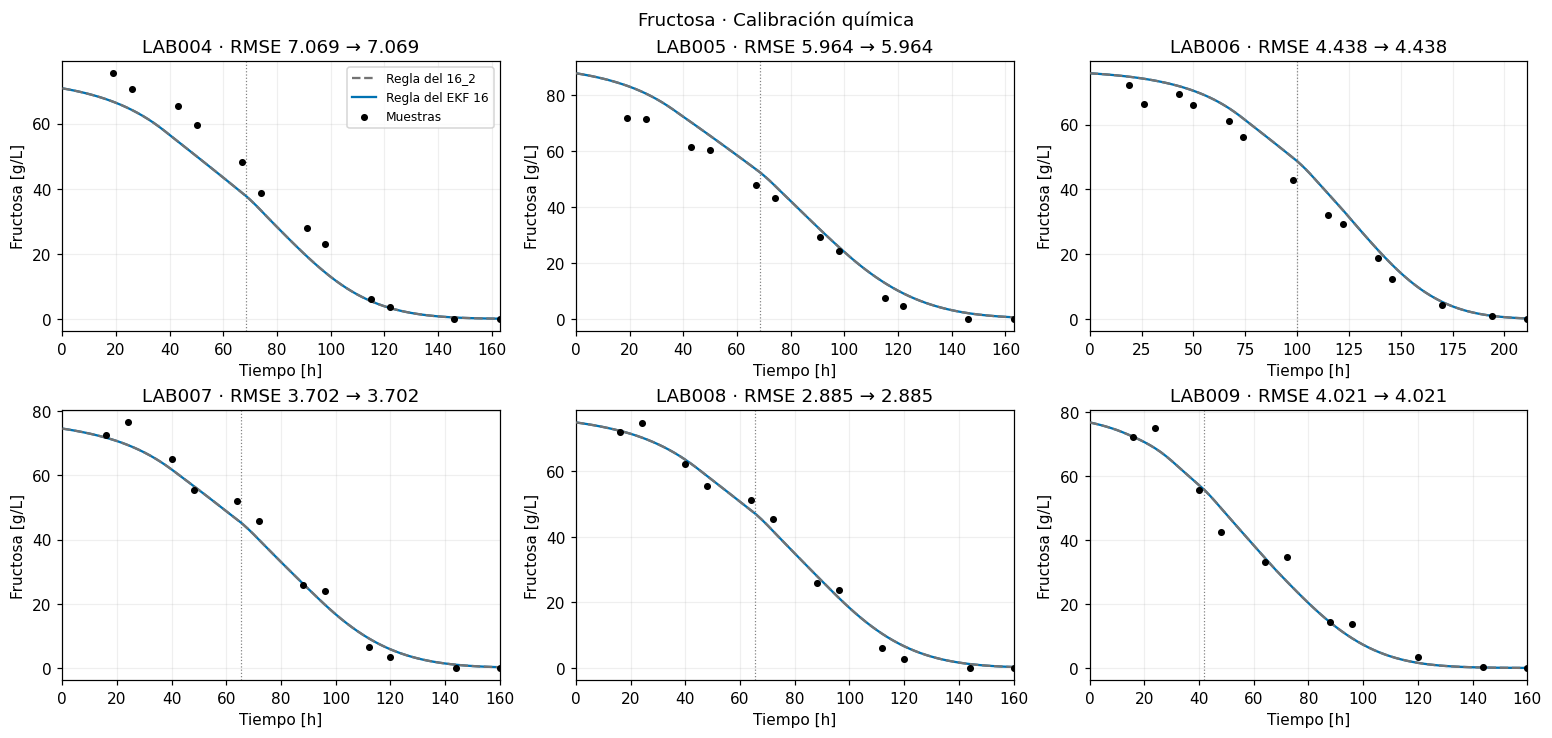

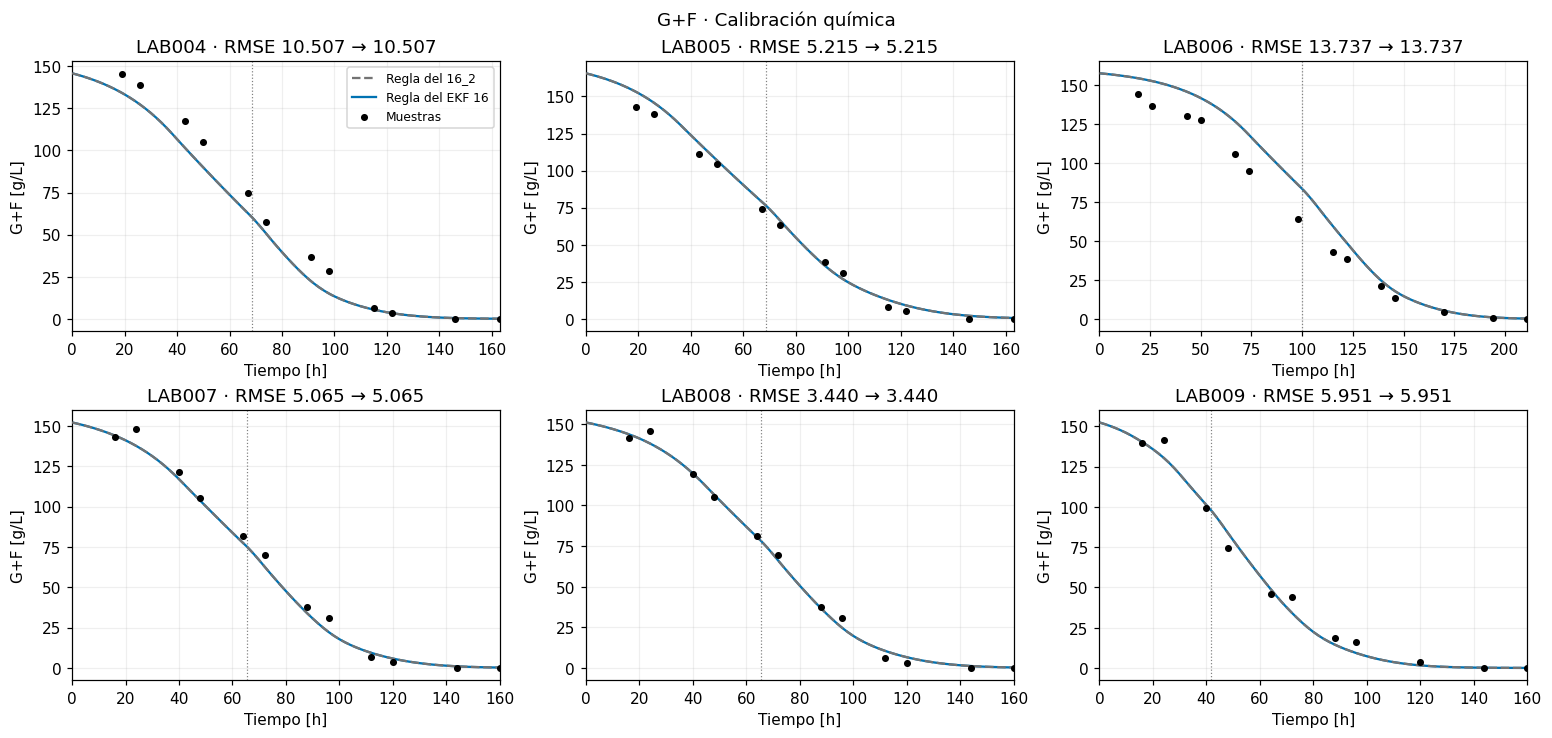

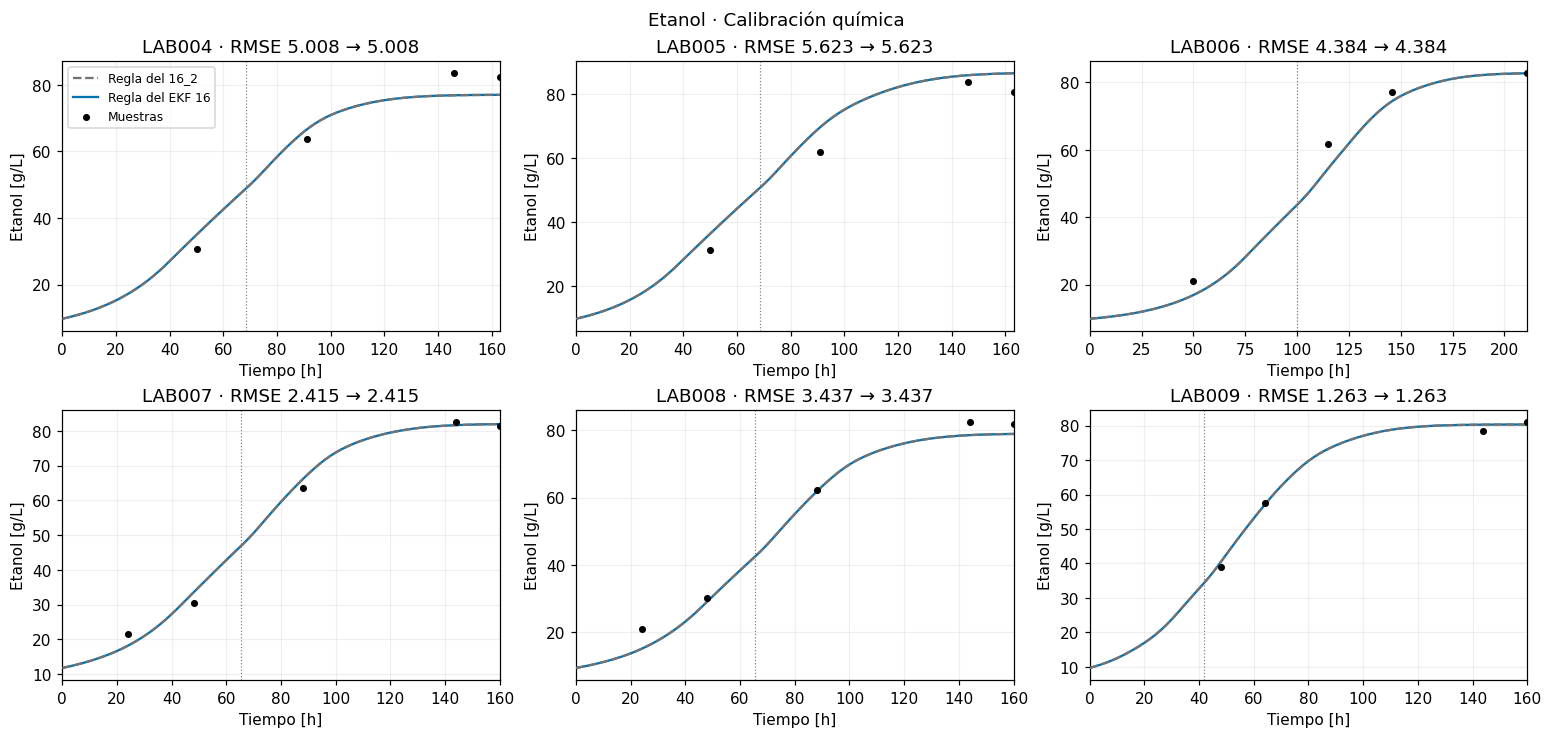

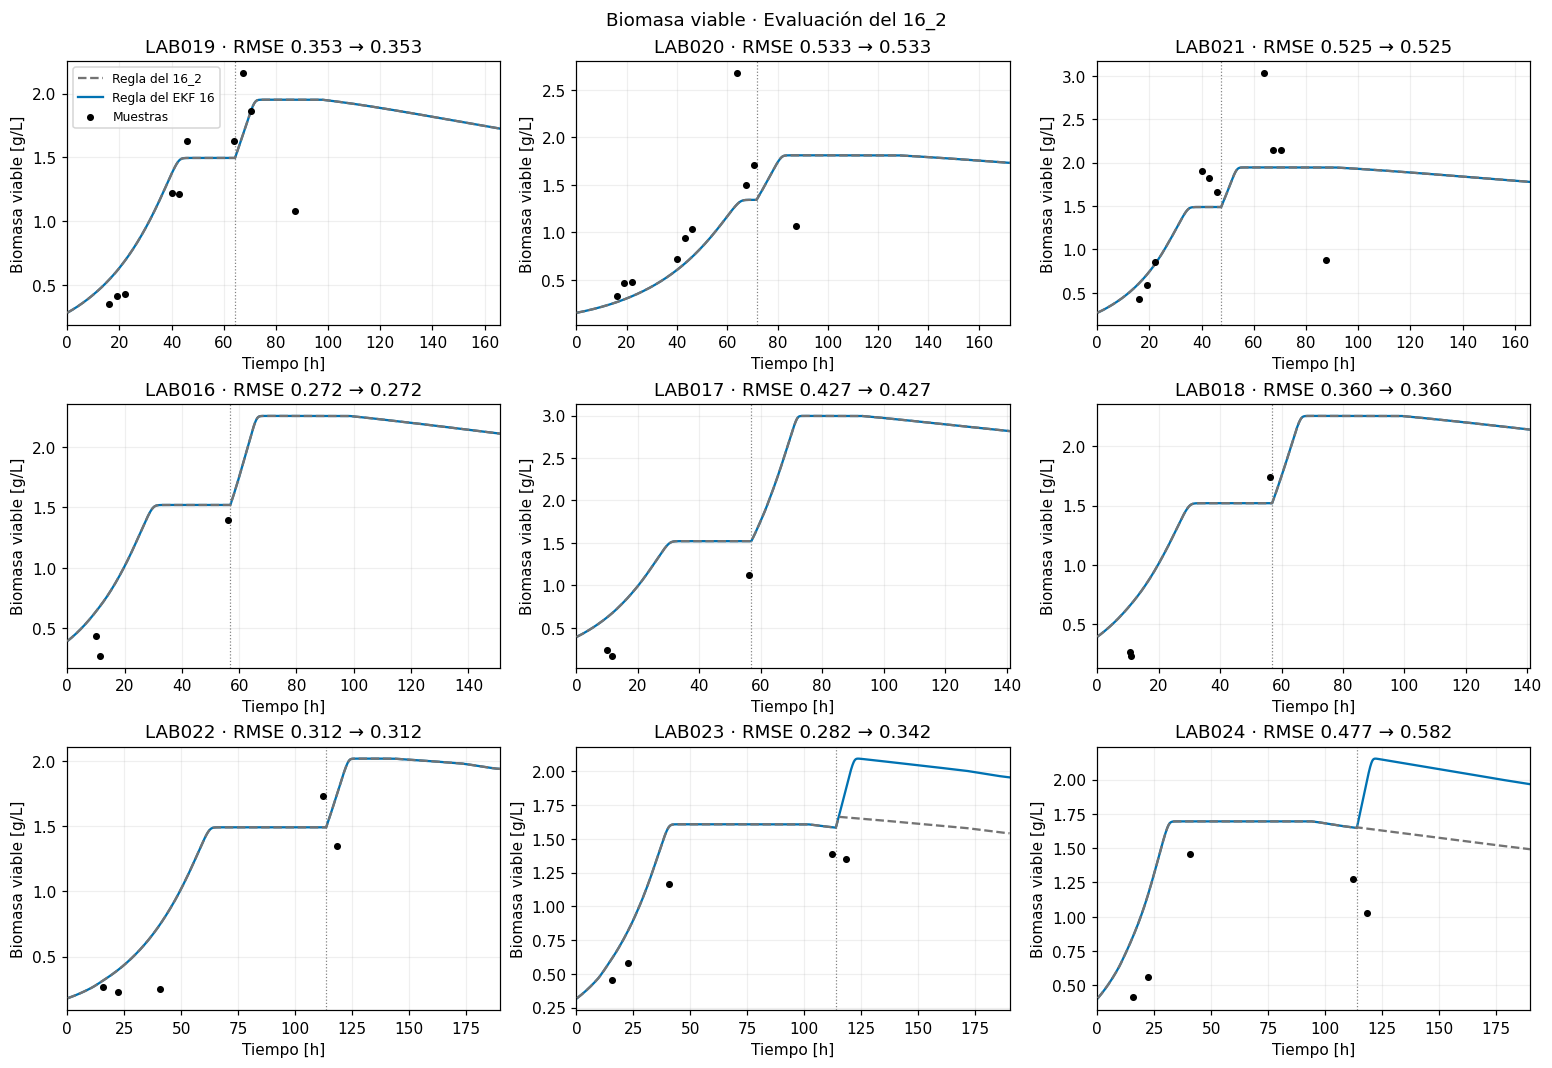

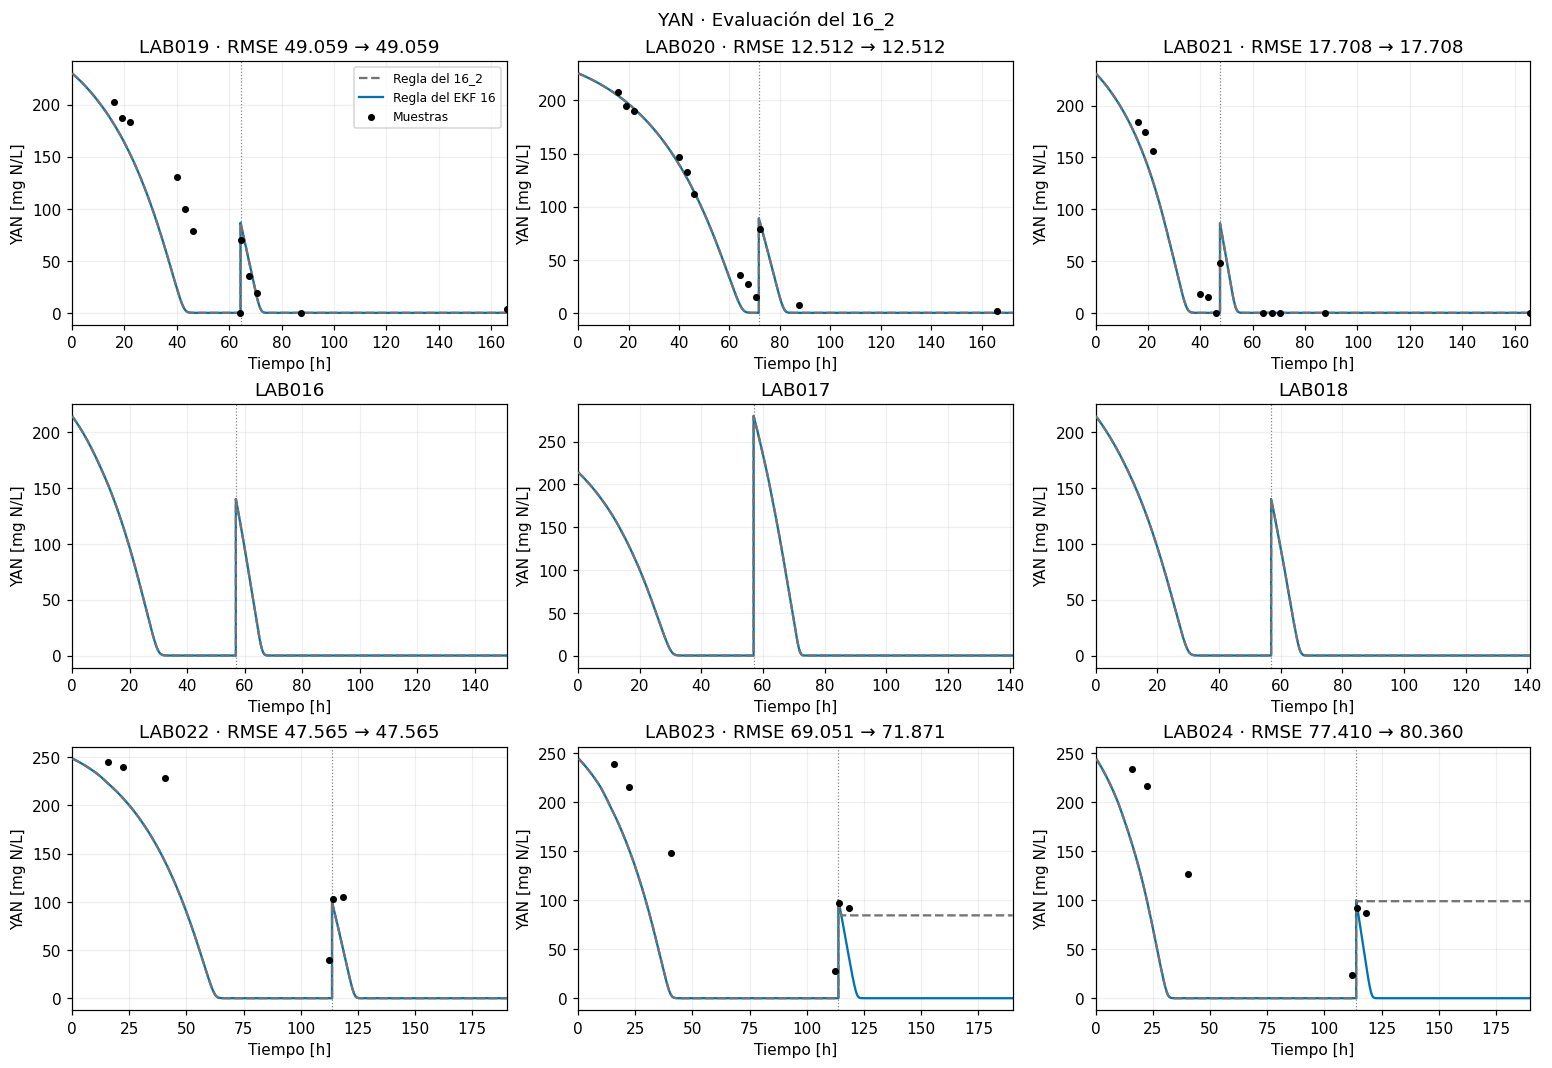

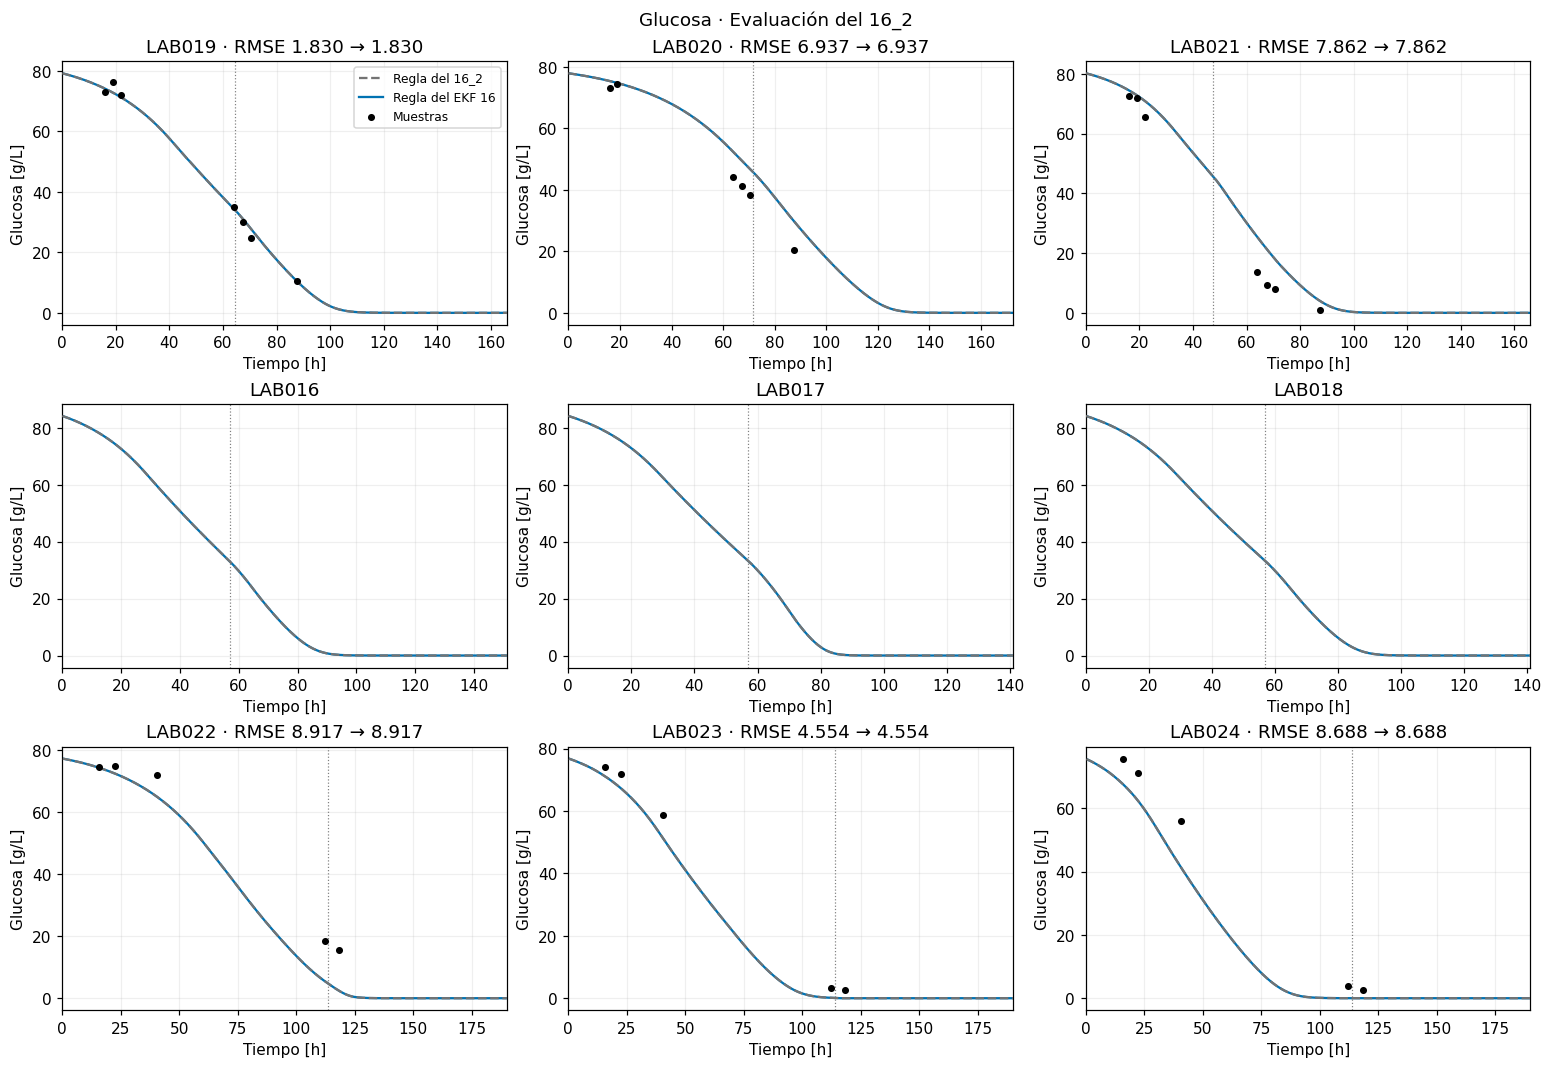

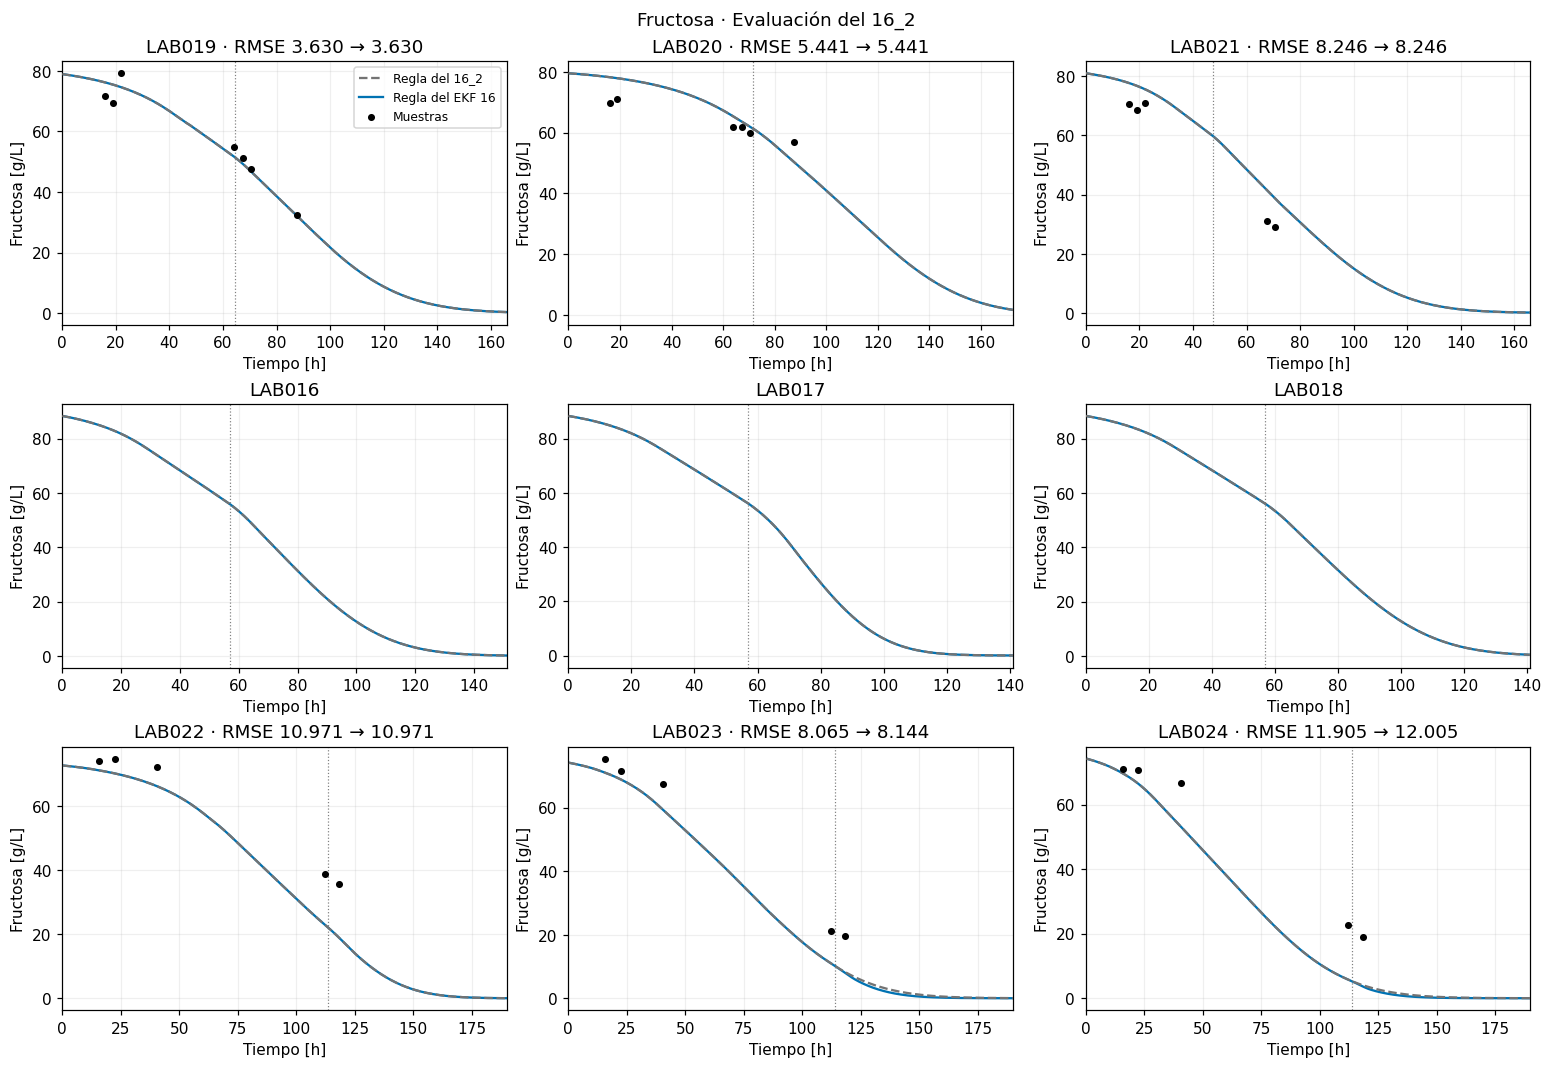

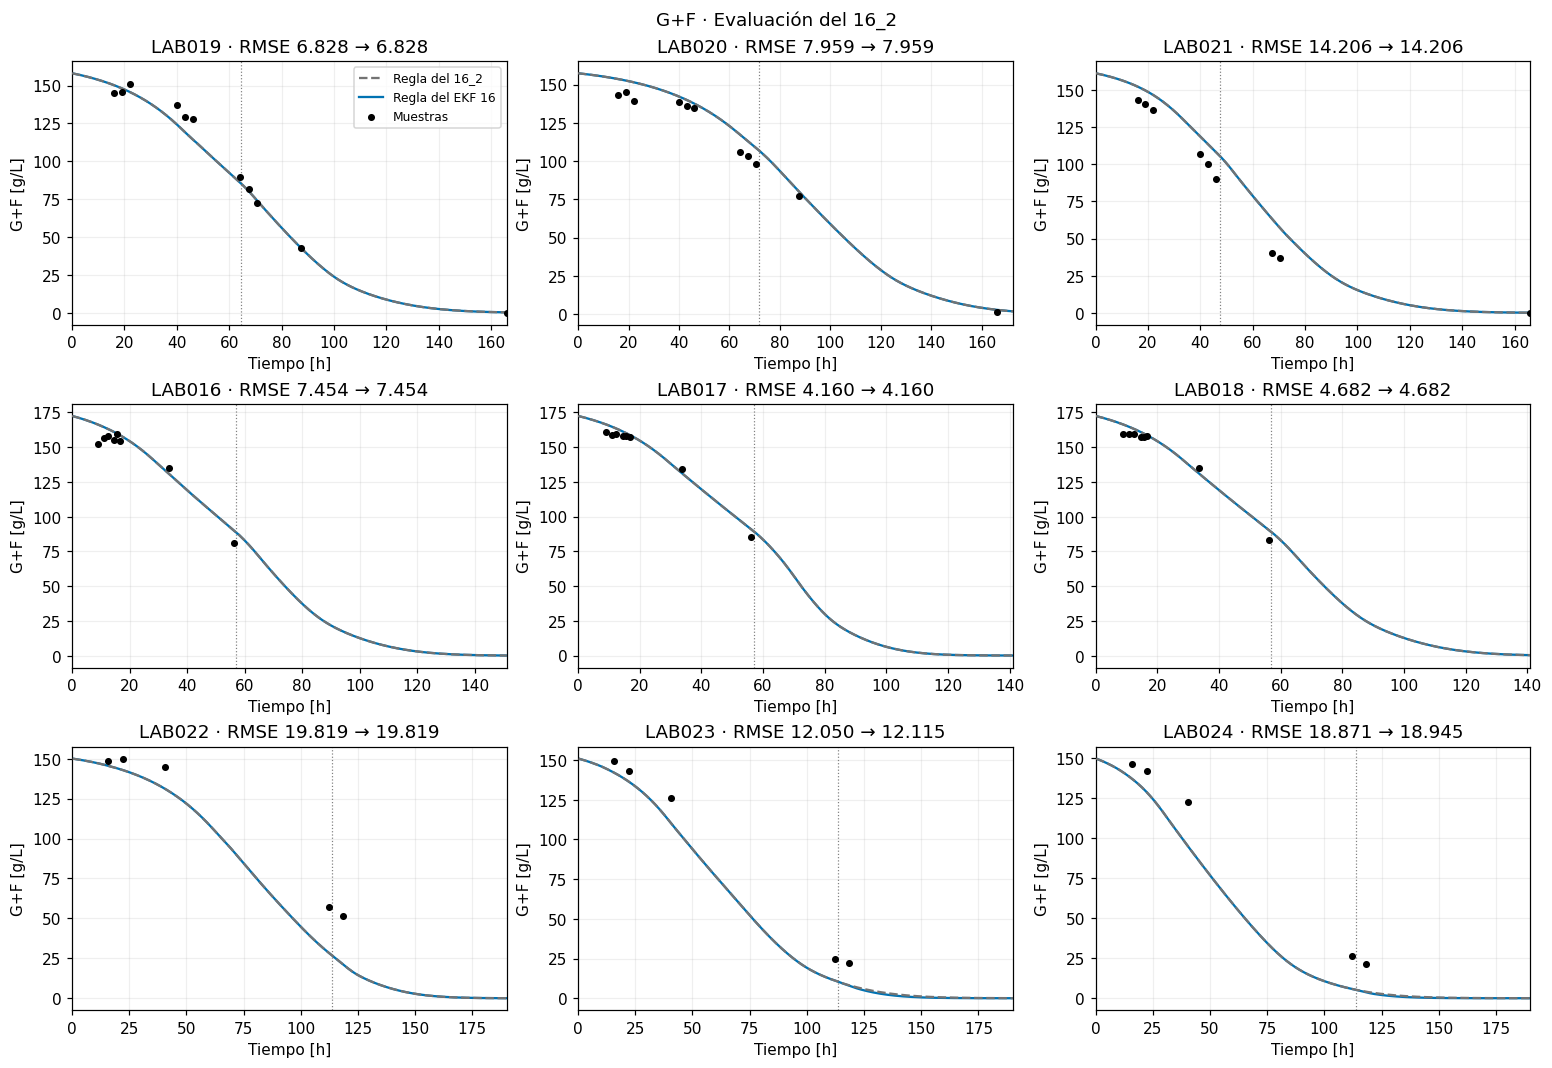

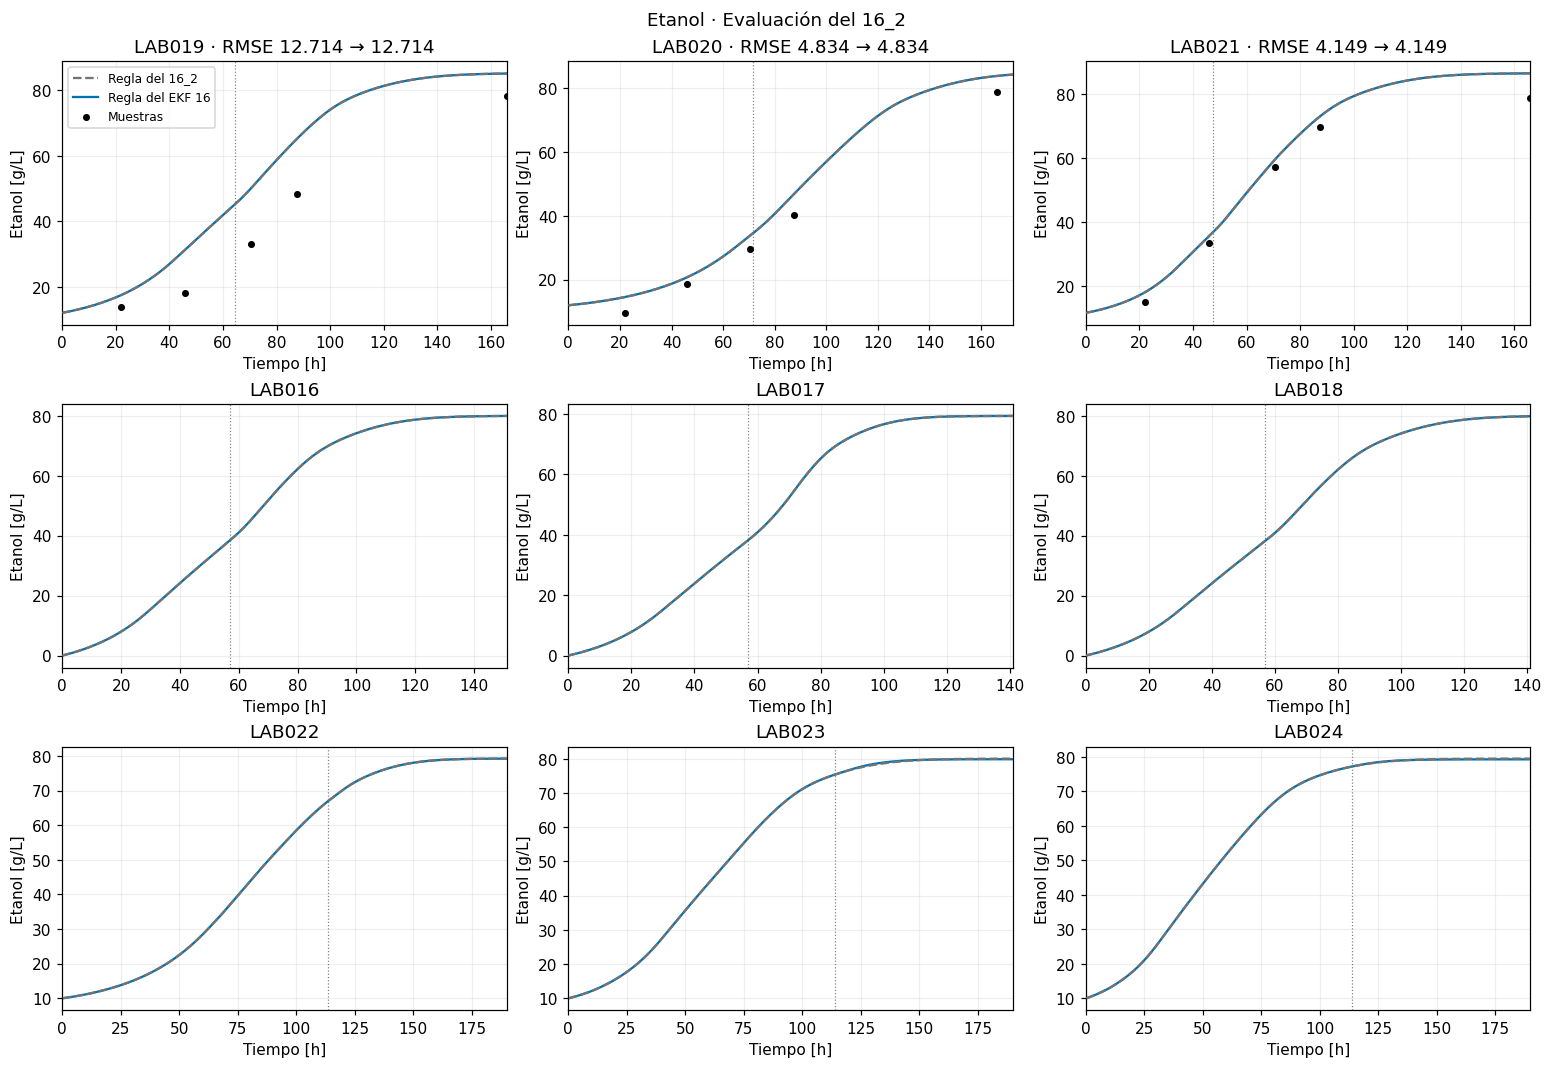

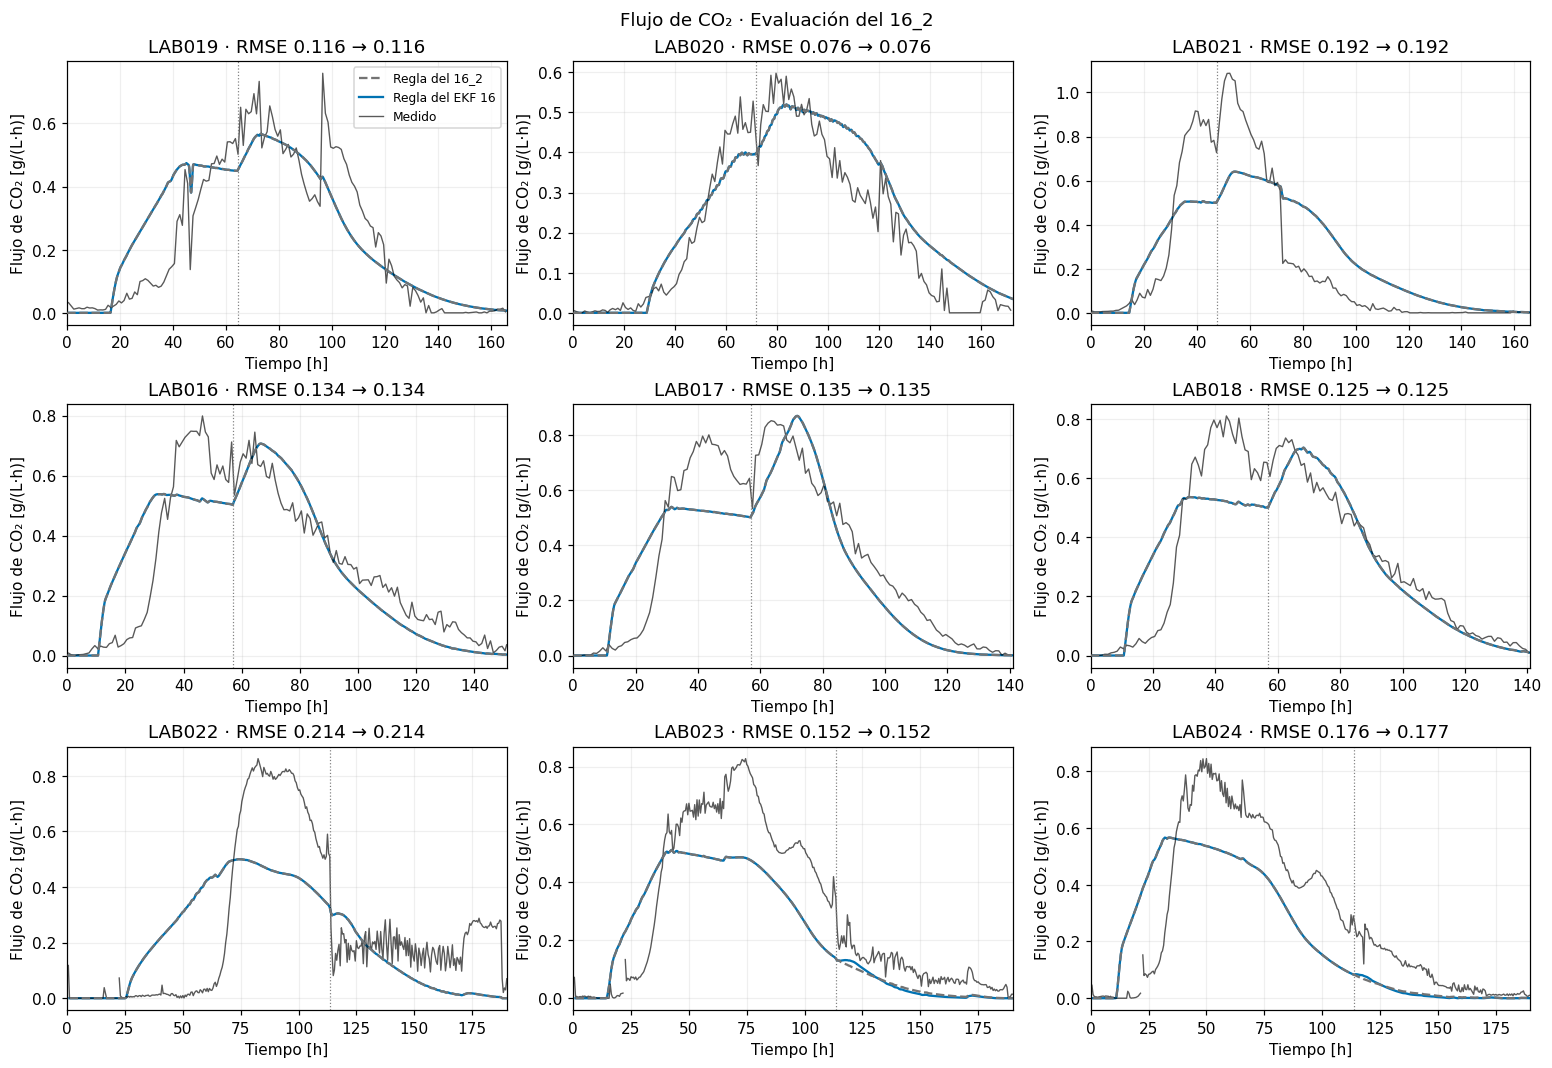

In [4]:
styles = {BASE: dict(color="#737373", linestyle="--", zorder=3),
          AVAILABLE: dict(color="#0072B2", zorder=2)}
for group, labs in (("Calibración química", tuple(training)),
                    ("Evaluación del 16_2", (*historical, *recent))):
    for state, (title, unit, _) in VARS.items():
        if state == "CO2" and group == "Calibración química":
            continue
        fig, axes = plt.subplots(len(labs) // 3, 3, figsize=(14, 3.3 * len(labs) // 3 + .6),
                                 layout="constrained")
        for ax, lab in zip(axes.flat, labs):
            for label in LABELS:
                frame = predicted(label, lab, state, plot=True)
                ax.plot(frame.index, frame.values, label=label, **styles[label])
            obs = samples[lab, state]
            if state == "CO2":
                if lab in recent:
                    obs = setup["holdout_flow"][lab]
                ax.plot(obs.index, obs.values, color="black", alpha=.65, lw=.9, label="Medido")
            else:
                ax.scatter(obs.index, obs.values, c="black", s=13, zorder=5, label="Muestras")
            for pulse, _ in batches[lab].pulses["N"]:
                ax.axvline(pulse, c="gray", ls=":", lw=.8)
            subtitle = lab
            if (lab, state) in rmse.index:
                old, new = rmse.loc[(lab, state), list(LABELS)]
                subtitle += f" · RMSE {old:.3f} → {new:.3f}"
            horizon = v.horizons[lab] if lab in historical else batches[lab].time[-1]
            ax.set(title=subtitle, xlabel="Tiempo [h]", ylabel=f"{title} [{unit}]", xlim=(0, horizon))
            ax.grid(alpha=.2)
        axes.flat[0].legend(fontsize=8)
        fig.suptitle(f"{title} · {group}")
        plt.show()

## Identificabilidad práctica de las constantes de inhibición y las tasas máximas

Se estudian \(K_{IG0}\), \(K_{IE0}\), \(\beta_{G0}\) y \(\beta_{F0}\) con los ocho parámetros libres y las mismas 283 observaciones ponderadas de LAB004–009 del ajuste actual. Se utiliza la regla de crecimiento por azúcar disponible. Las concentraciones iniciales, los pulsos, las temperaturas, las constantes fijas y las cotas se conservan.

Se analizan las sensibilidades respecto de los logaritmos de los parámetros, sus correlaciones locales y los perfiles del objetivo. En cada perfil se fija una constante de inhibición y se reajustan los otros siete parámetros. Esto permite observar cuánto se pueden compensar las tasas máximas y los rendimientos.

Las escalas del ajuste son ponderaciones empíricas y el rendimiento de etanol por fructosa está cerca de una cota. Las correlaciones corresponden a una aproximación lineal local. Los umbrales de aumento del objetivo de 1 % y 5 % se utilizan como referencias comparativas. Los rangos muestreados se presentan con esos umbrales y con las cotas utilizadas. El análisis evalúa la identificabilidad práctica de este experimento y parametrización.

Referencia metodológica: Raue y colaboradores (2009), *Structural and practical identifiability analysis of partially observed dynamical models by exploiting the profile likelihood*, https://doi.org/10.1093/bioinformatics/btp358.

Para reducir el ruido numérico en las derivadas se utilizan tolerancias de integración más estrictas. Se comprueba el cambio del objetivo respecto de la simulación original. El centro de los perfiles se obtiene refinando el vector guardado para el diagnóstico.

In [5]:
from scipy.optimize import least_squares

ident_config = json.loads((ROOT / "configs/models/without_transporters/calibration.json").read_text())
ident_names = [name for name in ident_config["bounds"] if name not in ("aN", "KNa", "Kn0", "Kd0")]
assert len(ident_names) == 8
ident_bounds = np.array([ident_config["bounds"][name] for name in ident_names])
ident_low, ident_high = np.log(ident_bounds).T
ident_support = setup["support"]
ident_count = sum(int(mask.sum()) for _, _, mask in ident_support)
assert ident_count == 283

ident_context = {**setup, "solve_ivp": integrate_sugar_events}
ident_chemistry = simulate_source.replace(old_guard, new_guard)
assert ident_chemistry.count("rtol=2e-6,atol=2e-8") == 1
ident_chemistry = ident_chemistry.replace("rtol=2e-6,atol=2e-8", "rtol=2e-8,atol=2e-10")
exec(compile(ident_chemistry, "16_3_identifiability", "exec"), ident_context)
ident_simulate = ident_context["simulate"]
ident_rejections = 0

def ident_residual(log_values):
    global ident_rejections
    parameters = {**theta, **dict(zip(ident_names, np.exp(log_values)))}
    try:
        predictions = {lab: ident_simulate(batch, parameters) for lab, batch in training.items()}
        residuals = np.concatenate([
            (predictions[batch.batch][state].to_numpy()[mask] - batch.observations[state][mask])
            / setup["sigma"](state, batch.observations[state][mask])
            for batch, state, mask in ident_support
        ])
        if not np.isfinite(residuals).all():
            raise FloatingPointError("Residuos no finitos")
        return residuals
    except (RuntimeError, ValueError, FloatingPointError):
        ident_rejections += 1
        return np.full(ident_count, 1e4)

ident_saved_log = np.log([theta[name] for name in ident_names])
ident_saved_residual = ident_residual(ident_saved_log)
ident_saved_mse = float(np.mean(ident_saved_residual**2))
print("Objetivo guardado:", weighted[AVAILABLE])
print("Objetivo con integración más precisa:", ident_saved_mse)
print("Diferencia relativa [%]:", 100 * (ident_saved_mse / weighted[AVAILABLE] - 1))
np.testing.assert_allclose(ident_saved_mse, weighted[AVAILABLE], rtol=2e-4)
ident_fit = least_squares(ident_residual, ident_saved_log, bounds=(ident_low, ident_high),
                          diff_step=1e-3, max_nfev=100, ftol=1e-7, xtol=1e-7, gtol=1e-6)
assert ident_fit.success, ident_fit.message
ident_center = ident_fit.x.copy() if ident_fit.fun @ ident_fit.fun <= ident_saved_residual @ ident_saved_residual else ident_saved_log.copy()
ident_center_residual = ident_residual(ident_center)
ident_center_mse = float(np.mean(ident_center_residual**2))
ident_center_theta = {**theta, **dict(zip(ident_names, np.exp(ident_center)))}
display(pd.DataFrame({"Ajuste actual": [theta[name] for name in ident_names],
                      "Centro del diagnóstico": np.exp(ident_center),
                      "Cambio %": 100 * (np.exp(ident_center) / np.exp(ident_saved_log) - 1)}, index=ident_names))
print("Centro del diagnóstico:", ident_center_mse, "convergencia", ident_fit.success)

Objetivo guardado: 4.715502281177189
Objetivo con integración más precisa: 4.715512961193721
Diferencia relativa [%]: 0.0002264873579793658


,Ajuste actual,Centro del diagnóstico,Cambio %
mu0,0.086722,0.086731,0.010679
betaG0,0.428291,0.426822,-0.342889
betaF0,0.593521,0.591737,-0.300588
Kig0,80.490799,81.056308,0.702576
Kie0,168.120412,170.075413,1.162858
Yxn,5.272368,5.272701,0.006318
Yeg,0.459547,0.458770,-0.168939
Yef,0.510598,0.511395,0.156224


Centro del diagnóstico: 4.715500847324523 convergencia True


## Sensibilidades y correlaciones locales

La matriz \(J\) contiene las derivadas de los residuos ponderados respecto de \(\log\theta\). Se calculan diferencias centrales con pasos de 0,001 y 0,0005. La norma de cada columna mide la sensibilidad a cambios relativos del parámetro. La descomposición en valores singulares muestra las combinaciones menos observables.

La matriz local de covarianza se aproxima mediante \([\sum r_i^2/(283-8)](J^TJ)^{-1}\). Sus correlaciones consideran simultáneamente los ocho parámetros. La pendiente local \(C_{\log\beta,\log K}/C_{\log K,\log K}\) estima la variación porcentual de una tasa que acompaña a una variación de 1 % de la constante de inhibición al reajustar los demás parámetros.

,Valor actual,Norma de sensibilidad,Diferencia de derivadas %,Desviación local de logaritmo
mu0,0.086722,115.142620,0.015540,0.024249
betaG0,0.428291,95.404508,0.012790,0.213530
betaF0,0.593521,83.148633,0.012270,0.284757
Kig0,80.490799,25.764034,0.039682,0.408060
Kie0,168.120412,27.344079,0.044063,0.597209
Yxn,5.272368,116.770869,0.025060,0.028519
Yeg,0.459547,110.872699,0.018885,0.190487
Yef,0.510598,100.891568,0.013770,0.194933


,mu0,betaG0,betaF0,Kig0,Kie0,Yxn,Yeg,Yef
mu0,1.0000,-0.0707,-0.0245,-0.1060,0.0245,0.3238,0.0238,-0.0157
betaG0,-0.0707,1.0000,-0.2075,-0.4202,-0.4583,0.0118,0.8709,-0.8578
betaF0,-0.0245,-0.2075,1.0000,-0.5933,-0.7090,0.0136,-0.6149,0.6257
Kig0,-0.1060,-0.4202,-0.5933,1.0000,0.6290,-0.0572,-0.1527,0.1513
Kie0,0.0245,-0.4583,-0.7090,0.6290,1.0000,-0.1556,0.0103,-0.0172
Yxn,0.3238,0.0118,0.0136,-0.0572,-0.1556,1.0000,0.0287,-0.0078
Yeg,0.0238,0.8709,-0.6149,-0.1527,0.0103,0.0287,1.0000,-0.9852
Yef,-0.0157,-0.8578,0.6257,0.1513,-0.0172,-0.0078,-0.9852,1.0000


Valores singulares: [185.49204489 113.37060501 102.26084351  81.95642749  47.47615305
   7.78126943   5.80578729   3.12294898]
Número de condición: 59.39643776994899
Rango numérico: 8 de 8


mu0       0.000180
betaG0    0.134164
betaF0    0.310388
Kig0     -0.459475
Kie0     -0.821271
Yxn       0.005083
Yeg      -0.002771
Yef       0.004796
Name: Combinación de menor sensibilidad en logaritmos, dtype: float64

,Constante,Tasa máxima,Correlación local,Cambio de tasa % por 1 % de constante
0,Kig0,betaG0,-0.4202,-0.2199
1,Kig0,betaF0,-0.5933,-0.4140
2,Kie0,betaG0,-0.4583,-0.1639
3,Kie0,betaF0,-0.7090,-0.3381


Constante Tasa máxima  Correlación local  Cambio de tasa % por 1 % de constante
     Kig0      betaG0            -0.4202                                -0.2199
     Kig0      betaF0            -0.5933                                -0.4140
     Kie0      betaG0            -0.4583                                -0.1639
     Kie0      betaF0            -0.7090                                -0.3381


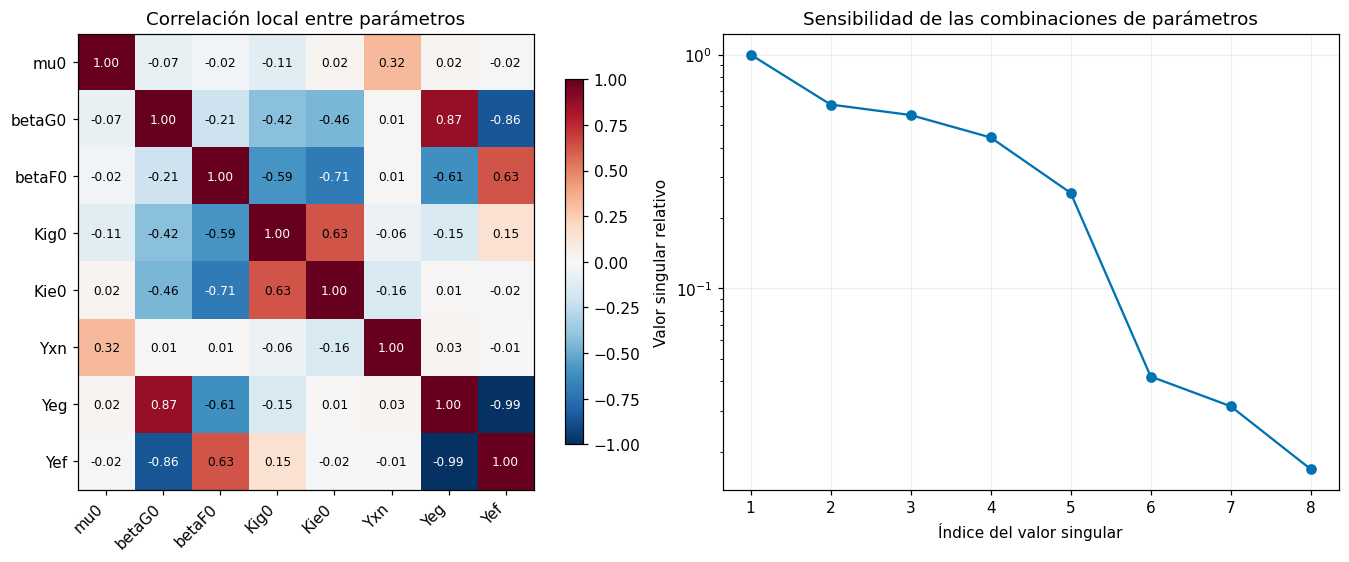

In [6]:
def ident_jacobian(step):
    columns = []
    for index, name in enumerate(ident_names):
        delta = np.zeros(len(ident_names))
        delta[index] = step
        columns.append((ident_residual(ident_saved_log + delta) - ident_residual(ident_saved_log - delta)) / (2 * step))
    return np.column_stack(columns)

ident_jac_coarse = ident_jacobian(1e-3)
ident_jac = ident_jacobian(5e-4)
ident_norms = np.linalg.norm(ident_jac, axis=0)
ident_step_error = np.linalg.norm(ident_jac - ident_jac_coarse, axis=0) / ident_norms
ident_u, ident_singular, ident_vt = np.linalg.svd(ident_jac, full_matrices=False)
ident_rank = int(np.sum(ident_singular > ident_singular[0] * max(ident_jac.shape) * np.finfo(float).eps))
assert ident_rank == len(ident_names), "La matriz local pierde rango numérico"
ident_variance = float(ident_saved_residual @ ident_saved_residual / (ident_count - len(ident_names)))
ident_covariance = (ident_vt.T * (ident_variance / ident_singular**2)) @ ident_vt
ident_standard = np.sqrt(np.diag(ident_covariance))
ident_correlation = ident_covariance / np.outer(ident_standard, ident_standard)
ident_corr_table = pd.DataFrame(ident_correlation, index=ident_names, columns=ident_names)
ident_sensitivity = pd.DataFrame({
    "Valor actual": [theta[name] for name in ident_names],
    "Norma de sensibilidad": ident_norms,
    "Diferencia de derivadas %": 100 * ident_step_error,
    "Desviación local de logaritmo": ident_standard,
}, index=ident_names)
display(ident_sensitivity.round(6))
display(ident_corr_table.round(4))
print("Valores singulares:", ident_singular)
print("Número de condición:", ident_singular[0] / ident_singular[-1])
print("Rango numérico:", ident_rank, "de", len(ident_names))
display(pd.Series(ident_vt[-1], index=ident_names, name="Combinación de menor sensibilidad en logaritmos"))

ident_pairs = []
for inhibition in ("Kig0", "Kie0"):
    k = ident_names.index(inhibition)
    for rate in ("betaG0", "betaF0"):
        b = ident_names.index(rate)
        ident_pairs.append({"Constante": inhibition, "Tasa máxima": rate,
                            "Correlación local": ident_correlation[k, b],
                            "Cambio de tasa % por 1 % de constante": ident_covariance[b, k] / ident_covariance[k, k]})
ident_pairs = pd.DataFrame(ident_pairs)
display(ident_pairs.round(4))
print(ident_pairs.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
heat = axes[0].imshow(ident_correlation, vmin=-1, vmax=1, cmap="RdBu_r")
axes[0].set_xticks(range(len(ident_names)), ident_names, rotation=45, ha="right")
axes[0].set_yticks(range(len(ident_names)), ident_names)
for row in range(len(ident_names)):
    for column in range(len(ident_names)):
        value = ident_correlation[row, column]
        axes[0].text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8,
                     color="white" if abs(value) > .65 else "black")
axes[0].set_title("Correlación local entre parámetros")
fig.colorbar(heat, ax=axes[0], shrink=.8)
axes[1].semilogy(range(1, len(ident_names) + 1), ident_singular / ident_singular[0], "o-", color="#0072B2")
axes[1].set(xlabel="Índice del valor singular", ylabel="Valor singular relativo", title="Sensibilidad de las combinaciones de parámetros")
axes[1].grid(alpha=.2)
plt.show()

## Perfiles de las constantes de inhibición

Se recorren valores positivos que incluyen las cotas de 5 y 1000 g/L, el centro del diagnóstico, fracciones y múltiplos de ese centro y 40 g/L. Para cada valor se muestran dos objetivos, uno con los demás parámetros conservados en el centro y otro tras reajustar los siete restantes.

El recorrido comienza en el centro y avanza por separado hacia valores menores y mayores, usando como inicio el último ajuste de cada dirección. Se repite desde el centro cuando el optimizador no converge o supera el objetivo del vector sin reajuste. Cada fila incluye la convergencia y los parámetros que alcanzan las proximidades de una cota. Los perfiles son aproximaciones numéricas locales dentro del intervalo explorado.

En estos perfiles se mantiene un único valor de \(K_{IG0}\) común a los seis lotes, como en 16_3. El 16_4 utiliza la regla \(S_0/4\) por lote, por lo que sus resultados corresponden a otra parametrización.

In [7]:
ident_profile_rows = []
ident_profile_vectors = {}
for inhibition in ("Kig0", "Kie0"):
    fixed_index = ident_names.index(inhibition)
    free_indices = np.array([i for i in range(len(ident_names)) if i != fixed_index])
    center_value = float(np.exp(ident_center[fixed_index]))
    values = np.unique(np.clip(np.r_[5., 40., center_value * np.array([.25, .5, 1., 2., 4.]), 1000.], 5., 1000.))
    directions = (sorted(values[values < center_value], reverse=True), sorted(values[values > center_value]))
    def add_profile(value, solution, cost, fixed_cost, success, evaluations, message):
        physical = dict(zip(ident_names, np.exp(solution)))
        near = [name for i, name in enumerate(ident_names) if i != fixed_index
                and min(abs(solution[i] - ident_low[i]), abs(ident_high[i] - solution[i])) < .02]
        ident_profile_vectors[inhibition, value] = solution.copy()
        ident_profile_rows.append({"Constante": inhibition, "Valor fijo": value,
            "MSE sin reajuste": fixed_cost, "MSE perfil": cost,
            "Convergencia": success, "Evaluaciones": evaluations, "Mensaje": str(message),
            "Cerca de cota": ", ".join(near), **physical})
    add_profile(center_value, ident_center, ident_center_mse, ident_center_mse, True, 0, "Centro")
    for direction in directions:
        warm = ident_center.copy()
        for value in direction:
            log_fixed = float(np.log(value))
            def expand(free):
                full = ident_center.copy()
                full[free_indices] = free
                full[fixed_index] = log_fixed
                return full
            def objective(free):
                return ident_residual(expand(free))
            fixed_vector = ident_center.copy()
            fixed_vector[fixed_index] = log_fixed
            fixed_cost = float(np.mean(ident_residual(fixed_vector)**2))
            solution = least_squares(objective, np.clip(warm[free_indices], ident_low[free_indices]+1e-10, ident_high[free_indices]-1e-10),
                bounds=(ident_low[free_indices], ident_high[free_indices]), diff_step=1e-3,
                max_nfev=100, ftol=2e-6, xtol=2e-6, gtol=1e-5)
            if not solution.success or np.mean(solution.fun**2) > fixed_cost * (1 + 1e-6):
                retry = least_squares(objective, np.clip(ident_center[free_indices], ident_low[free_indices]+1e-10, ident_high[free_indices]-1e-10),
                    bounds=(ident_low[free_indices], ident_high[free_indices]), diff_step=1e-3,
                    max_nfev=180, ftol=2e-6, xtol=2e-6, gtol=1e-5)
                if retry.success and (not solution.success or retry.fun @ retry.fun < solution.fun @ solution.fun):
                    solution = retry
            warm = expand(solution.x)
            cost = float(np.mean(solution.fun**2))
            assert cost <= fixed_cost * (1 + 1e-4), "El perfil supera al vector factible sin reajuste"
            add_profile(value, warm, cost, fixed_cost, solution.success, solution.nfev, solution.message)
            print(inhibition, "fijo", round(value, 5), "MSE", round(cost, 7),
                  "convergencia", solution.success, "nfev", solution.nfev, flush=True)
ident_profiles = pd.DataFrame(ident_profile_rows).sort_values(["Constante", "Valor fijo"]).reset_index(drop=True)
ident_best_mse = min(ident_center_mse, ident_profiles["MSE perfil"].min())
ident_profiles["Aumento del objetivo %"] = 100 * (ident_profiles["MSE perfil"] / ident_best_mse - 1)
ident_profiles["Aumento sin reajuste %"] = 100 * (ident_profiles["MSE sin reajuste"] / ident_best_mse - 1)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(ident_profiles[["Constante", "Valor fijo", "MSE perfil", "Aumento del objetivo %",
                           "Convergencia", "betaG0", "betaF0", "Yef", "Cerca de cota"]].round(6))
print("Rechazos de integración:", ident_rejections)
print("Perfiles convergentes:", int(ident_profiles.Convergencia.sum()), "de", len(ident_profiles))

Kig0 fijo 40.52815 MSE 4.7635096 convergencia True nfev 11
Kig0 fijo 40.0 MSE 4.7655786 convergencia True nfev 3
Kig0 fijo 20.26408 MSE 4.9408627 convergencia True nfev 8
Kig0 fijo 5.0 MSE 5.4728346 convergencia True nfev 20
Kig0 fijo 162.11262 MSE 4.7419441 convergencia True nfev 11
Kig0 fijo 324.22523 MSE 4.7872854 convergencia True nfev 11
Kig0 fijo 1000.0 MSE 4.8551076 convergencia True nfev 9
Kie0 fijo 85.03771 MSE 4.7403604 convergencia True nfev 7
Kie0 fijo 42.51885 MSE 4.8523329 convergencia True nfev 7
Kie0 fijo 40.0 MSE 4.8675841 convergencia True nfev 5
Kie0 fijo 5.0 MSE 5.5855585 convergencia True nfev 13
Kie0 fijo 340.15083 MSE 4.7258835 convergencia True nfev 7
Kie0 fijo 680.30165 MSE 4.7403569 convergencia True nfev 6
Kie0 fijo 1000.0 MSE 4.7465702 convergencia True nfev 5


,Constante,Valor fijo,MSE perfil,Aumento del objetivo %,Convergencia,betaG0,betaF0,Yef,Cerca de cota
0,Kie0,5.000000,5.585559,18.451014,True,2.701549,9.283770,0.511400,Yef
1,Kie0,40.000000,4.867584,3.225177,True,0.654256,1.318716,0.511400,Yef
2,Kie0,42.518853,4.852333,2.901750,True,0.636949,1.257552,0.511400,Yef
3,Kie0,85.037707,4.740360,0.527187,True,0.497181,0.803848,0.511398,Yef
4,Kie0,170.075413,4.715501,0.000000,True,0.426822,0.591737,0.511395,Yef
5,Kie0,340.150826,4.725884,0.220182,True,0.391946,0.492042,0.511399,Yef
6,Kie0,680.301653,4.740357,0.527113,True,0.374421,0.442737,0.511400,Yef
7,Kie0,1000.000000,4.746570,0.658878,True,0.368936,0.427558,0.511400,Yef
8,Kig0,5.000000,5.472835,16.060516,True,0.738502,6.303726,0.511400,Yef
9,Kig0,20.264077,4.940863,4.779171,True,0.594723,1.545671,0.497194,


Rechazos de integración: 0
Perfiles convergentes: 16 de 16


## Compensación observada y estabilidad del objetivo

Se muestran los perfiles y las tasas máximas elegidas al reajustar. La zona sombreada de las tasas corresponde al rango de valores muestreados con aumento del objetivo de hasta 5 %. Se incluyen las curvas sin reajuste para medir la reducción del deterioro que se obtiene al permitir la compensación.

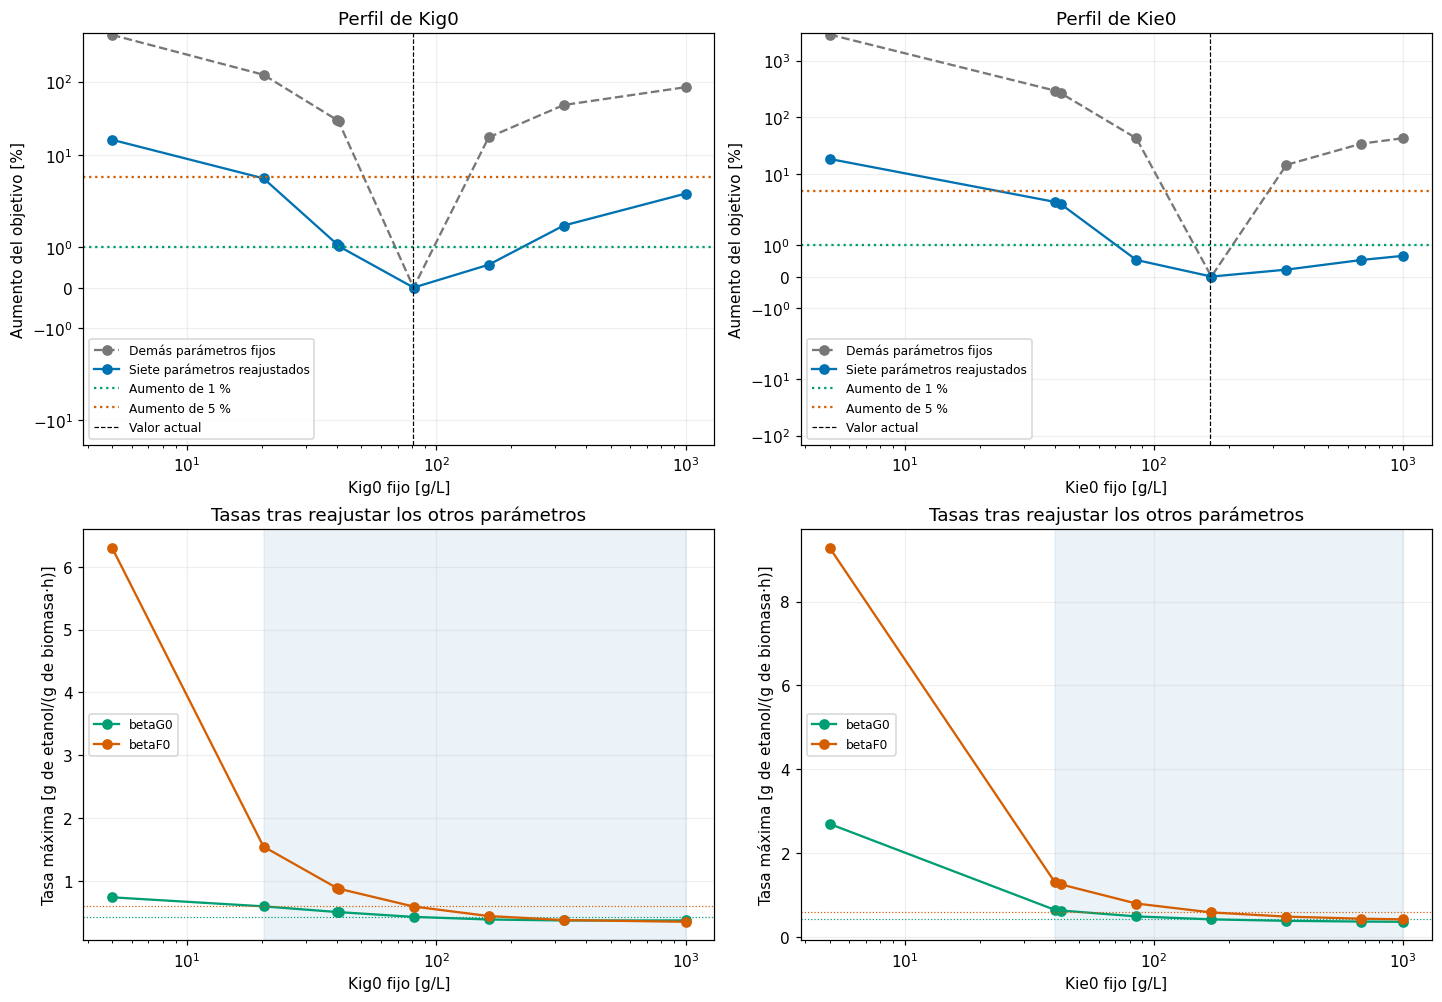

,Constante,Umbral de aumento %,Menor valor muestreado,Mayor valor muestreado,Número de puntos,Alcanza una cota explorada,Menor betaG0,Mayor betaG0,Menor betaF0,Mayor betaF0
0,Kig0,1.0,81.056308,162.112615,2,False,0.385733,0.426822,0.440586,0.591737
1,Kig0,5.0,20.264077,1000.000000,7,True,0.369877,0.594723,0.348983,1.545671
2,Kie0,1.0,85.037707,1000.000000,5,True,0.368936,0.497181,0.427558,0.803848
3,Kie0,5.0,40.000000,1000.000000,7,True,0.368936,0.654256,0.427558,1.318716


Constante  Umbral de aumento %  Menor valor muestreado  Mayor valor muestreado  Número de puntos  Alcanza una cota explorada  Menor betaG0  Mayor betaG0  Menor betaF0  Mayor betaF0
     Kig0                  1.0               81.056308              162.112615                 2                       False      0.385733      0.426822      0.440586      0.591737
     Kig0                  5.0               20.264077             1000.000000                 7                        True      0.369877      0.594723      0.348983      1.545671
     Kie0                  1.0               85.037707             1000.000000                 5                        True      0.368936      0.497181      0.427558      0.803848
     Kie0                  5.0               40.000000             1000.000000                 7                        True      0.368936      0.654256      0.427558      1.318716


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
for column, inhibition in enumerate(("Kig0", "Kie0")):
    frame = ident_profiles.loc[ident_profiles.Constante.eq(inhibition)]
    valid = frame.Convergencia
    axes[0, column].plot(frame["Valor fijo"], frame["Aumento sin reajuste %"], "o--", color="#777777", label="Demás parámetros fijos")
    axes[0, column].plot(frame.loc[valid, "Valor fijo"], frame.loc[valid, "Aumento del objetivo %"], "o-", color="#0072B2", label="Siete parámetros reajustados")
    axes[0, column].axhline(1, color="#009E73", linestyle=":", label="Aumento de 1 %")
    axes[0, column].axhline(5, color="#D55E00", linestyle=":", label="Aumento de 5 %")
    axes[0, column].axvline(theta[inhibition], color="black", linestyle="--", linewidth=.8, label="Valor actual")
    axes[0, column].set(xscale="log", yscale="symlog", xlabel=f"{inhibition} fijo [g/L]",
                        ylabel="Aumento del objetivo [%]", title=f"Perfil de {inhibition}")
    for rate, color in (("betaG0", "#009E73"), ("betaF0", "#D55E00")):
        axes[1, column].plot(frame.loc[valid, "Valor fijo"], frame.loc[valid, rate], "o-", color=color, label=rate)
        axes[1, column].axhline(theta[rate], color=color, linestyle=":", linewidth=.8)
    accepted = frame.loc[valid & frame["Aumento del objetivo %"].le(5)]
    if len(accepted):
        axes[1, column].axvspan(accepted["Valor fijo"].min(), accepted["Valor fijo"].max(), color="#0072B2", alpha=.08)
    axes[1, column].set(xscale="log", xlabel=f"{inhibition} fijo [g/L]",
                        ylabel="Tasa máxima [g de etanol/(g de biomasa·h)]", title="Tasas tras reajustar los otros parámetros")
    for row in range(2):
        axes[row, column].grid(alpha=.2)
        axes[row, column].legend(fontsize=8)
plt.show()

ident_ranges = []
for inhibition in ("Kig0", "Kie0"):
    frame = ident_profiles.loc[ident_profiles.Constante.eq(inhibition) & ident_profiles.Convergencia]
    for limit in (1., 5.):
        accepted = frame.loc[frame["Aumento del objetivo %"].le(limit)]
        assert len(accepted)
        ident_ranges.append({"Constante": inhibition, "Umbral de aumento %": limit,
            "Menor valor muestreado": accepted["Valor fijo"].min(),
            "Mayor valor muestreado": accepted["Valor fijo"].max(),
            "Número de puntos": len(accepted),
            "Alcanza una cota explorada": bool(accepted["Valor fijo"].le(5.00001).any() or accepted["Valor fijo"].ge(999.999).any()),
            "Menor betaG0": accepted.betaG0.min(), "Mayor betaG0": accepted.betaG0.max(),
            "Menor betaF0": accepted.betaF0.min(), "Mayor betaF0": accepted.betaF0.max()})
ident_ranges = pd.DataFrame(ident_ranges)
with pd.option_context("display.max_columns", None):
    display(ident_ranges.round(6))
print(ident_ranges.round(6).to_string(index=False))

## Lectura del diagnóstico

Las correlaciones y pendientes locales cuantifican la compensación cerca del ajuste actual. Los perfiles permiten evaluar la extensión de esa compensación cuando los parámetros cambian más. Los rangos siguientes describen los puntos explorados que conservan el objetivo dentro del umbral elegido. Su interpretación depende de las cotas, el muestreo y la convergencia registrados.

In [9]:
for row in ident_pairs.to_dict("records"):
    print(f"{row['Constante']} / {row['Tasa máxima']}: correlación {row['Correlación local']:.3f}; "
          f"cambio local de tasa {row['Cambio de tasa % por 1 % de constante']:.3f} % por 1 % de constante.")
for row in ident_ranges.to_dict("records"):
    print(f"{row['Constante']}: con aumento del objetivo de hasta {row['Umbral de aumento %']:.0f} %, "
          f"los puntos aceptados van de {row['Menor valor muestreado']:.3f} a {row['Mayor valor muestreado']:.3f} g/L.")
print("Máxima diferencia relativa entre derivadas [%]:", 100 * ident_step_error.max())
print("Yef actual y cota superior:", theta["Yef"], np.exp(ident_high[ident_names.index("Yef")]))
print("Análisis completado con", ident_count, "observaciones y", len(ident_names), "parámetros libres.")
assert np.array_equal(np.log([theta[name] for name in ident_names]), ident_saved_log)
assert np.isfinite(ident_jac).all() and np.isfinite(ident_correlation).all()
assert ident_profiles.Convergencia.all(), "Revisar las filas de perfil que no convergen"

Kig0 / betaG0: correlación -0.420; cambio local de tasa -0.220 % por 1 % de constante.
Kig0 / betaF0: correlación -0.593; cambio local de tasa -0.414 % por 1 % de constante.
Kie0 / betaG0: correlación -0.458; cambio local de tasa -0.164 % por 1 % de constante.
Kie0 / betaF0: correlación -0.709; cambio local de tasa -0.338 % por 1 % de constante.
Kig0: con aumento del objetivo de hasta 1 %, los puntos aceptados van de 81.056 a 162.113 g/L.
Kig0: con aumento del objetivo de hasta 5 %, los puntos aceptados van de 20.264 a 1000.000 g/L.
Kie0: con aumento del objetivo de hasta 1 %, los puntos aceptados van de 85.038 a 1000.000 g/L.
Kie0: con aumento del objetivo de hasta 5 %, los puntos aceptados van de 40.000 a 1000.000 g/L.
Máxima diferencia relativa entre derivadas [%]: 0.044062689881034574
Yef actual y cota superior: 0.5105977085906764 0.5114
Análisis completado con 283 observaciones y 8 parámetros libres.


## Resumen de la ejecución guardada

La matriz de sensibilidades tiene rango numérico 8 de 8 y un número de condición de 59,4. La diferencia máxima de las derivadas calculadas con los dos pasos es 0,044 %. La combinación de menor sensibilidad está dominada por las dos constantes de inhibición y las tasas máximas de producción de etanol.

Las correlaciones locales de \(K_{IG0}\) con \(\beta_{G0}\) y \(\beta_{F0}\) son −0,420 y −0,593. Las de \(K_{IE0}\) con esas tasas son −0,458 y −0,709. Al aumentar una constante de inhibición, el reajuste local tiende a reducir las tasas máximas. La correlación entre los rendimientos \(Y_{E/G}\) y \(Y_{E/F}\) alcanza −0,985, por lo que también intervienen en la compensación.

| Constante | Valores de la malla con aumento del objetivo de hasta 1 % [g/L] | Valores de la malla con aumento del objetivo de hasta 5 % [g/L] |
|---|---:|---:|
| \(K_{IG0}\) | 81,06–162,11 | 20,26–1000 |
| \(K_{IE0}\) | 85,04–1000 | 40–1000 |

Los 16 puntos de perfil convergen. En el perfil de glucosa, el rango con aumento de hasta 5 % incluye valores de \(\beta_{F0}\) entre 0,349 y 1,546. En el de etanol incluye valores entre 0,428 y 1,319, en g de etanol por g de biomasa y hora. La cercanía de las curvas ajustadas puede coexistir con cambios importantes de estos parámetros.

Estos rangos describen los puntos ensayados y dependen de las cotas, los otros parámetros libres y el umbral comparativo elegido. La exploración alcanza la cota de 1000 g/L y varios ajustes alcanzan la proximidad de la cota de \(Y_{E/F}\). Las correlaciones locales utilizan una aproximación lineal que requiere esa misma cautela cerca de las cotas. Los resultados indican una identificabilidad práctica limitada de las constantes de inhibición con las observaciones de calibración disponibles.